# IIT(ISM) Dhanbad

## Department of Mathematics and Computing

# Air Quality Across Indian Cities (2015–2020): A Data Visualization Study

*1st sem. M.Tech Data Analytics · Data Visualization Lab project*

Name : TANMOY MONDAL

Roll no. : 26MT0601

Git Repositoray : 


## 1. Problem statement
Air pollution in India differs sharply by city, season and year, but the monitoring data that describes it is incomplete and contains errors. This project uses daily readings from 26 Indian cities to answer four questions:

1. **How polluted is each city** compared with the national standard (NAAQS) for PM2.5?
2. **How strongly does season drive pollution**, and does the pattern look the same everywhere?
3. **Can the data be trusted?** Where are the gaps, the instrument caps and the copied or inconsistent columns, and what is the safest way to deal with them?
4. **What happened during the 2020 COVID-19 lockdown** compared with the same dates in earlier years?

The analysis is organised as 22 numbered questions (Q1–Q22). Every chart answers one stated question and is followed by an **Insight** that gives the numbers behind the conclusion. No machine-learning models are used; the focus is on visual and statistical description that can be explained and checked.

## 2. Dataset
- **Source:** Kaggle, *Air Quality Data in India (2015–2020)*, file `city_day.csv`, compiled from Central Pollution Control Board (CPCB) data.
- **Size:** 29,531 daily rows, 26 cities, 1 Jan 2015 to 1 Jul 2020, 16 columns.
- **Place the file at** `data/raw/city_day.csv` (it is not committed to the repository).

| Column | Meaning |
|---|---|
| `City`, `Date` | Monitoring city and day (one row per city per day) |
| `PM2.5`, `PM10` | Particulate matter below 2.5 / 10 micrometres (µg/m³) |
| `NO`, `NO2`, `NOx` | Nitrogen oxides (traffic and combustion tracers) |
| `NH3`, `CO`, `SO2`, `O3` | Ammonia, carbon monoxide, sulphur dioxide, ozone |
| `Benzene`, `Toluene`, `Xylene` | Volatile organic compounds |
| `AQI`, `AQI_Bucket` | CPCB Air Quality Index and its category (Good to Severe) |

## 3. How this notebook is organised
| Phase | Questions | What it does | Main techniques |
|---|---|---|---|
| 1. Setup and inspection | – | Load the data and inspect structure, coverage, missing values and duplicates | `info`, `describe`, `groupby`, `isna` |
| 2. Cleaning and data-quality audit | – | Fix dtypes, remove copied values, fill only short gaps, exclude an unreliable series | `pd.cut`, `Categorical`, `interpolate`, Spearman correlation |
| 3. Distributions | Q1–Q5 | Shape of PM2.5, exceedance of the standard, differences between cities and seasons | Histogram, KDE, ECDF, skewness, box and violin plots |
| 4. Time series | Q6–Q10 | Data availability, trends, smoothing, seasonality, lockdown comparison | Resampling, rolling means, seasonal decomposition |
| 5. Comparisons | Q11–Q15 | Compare cities, seasons and years | Grouped, stacked and normalized bar charts, subplots |
| 6. Relationships | Q16–Q19 | How pollutants relate to each other | Multivariate scatter, correlation heatmap, faceting, KDE |
| 7. Interactive charts | Q20–Q22 | Let the reader explore the findings | Plotly hover, dropdown, range slider, bubble map |
| 8. Findings | – | Key findings, limitations and conclusion | – |

## 4. Conventions used throughout
- **Core cities.** Eight cities have records for at least 90% of all days: Ahmedabad, Bengaluru, Chennai, Delhi, Hyderabad, Lucknow, Mumbai and Patna. Comparisons between cities use only these, because comparing a city that has five months of data with one that has five years would be unfair.
- **PM2.5 standard.** The Indian 24-hour NAAQS limit for PM2.5 is **60 µg/m³**; it appears as a red dashed line in most charts.
- **Seasons** (the same calendar rule for every city): Winter = Dec–Feb, Summer = Mar–May, Monsoon = Jun–Sep, Post-monsoon = Oct–Nov.
- **Lockdown window.** India's national lockdown began on 25 March 2020. The window 25 Mar–30 Jun 2020 is used for the lockdown comparison.
- **Folder layout.** The notebook lives in `notebooks/`; data is read from `../data/` and figures are saved to `../outputs/figures/`.
- **Python packages:** pandas, numpy, matplotlib, seaborn, statsmodels, plotly, jupyter (see `requirements.txt`).

---
# Phase 1: Setup, loading and inspection

**Goal.** Understand what the raw file contains before changing anything: its size, column types, date range, per-city coverage, missing values and duplicates. Every cleaning decision in Phase 2 is based on what is found here.

In [1]:
# Imports and global settings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose   # Phase 4
import plotly.express as px                                # Phase 7

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

**Load the data.** `parse_dates=["Date"]` converts the Date column to a true datetime at load time. This is needed later for resampling, rolling windows and seasonal decomposition.

In [2]:
# Load the raw file; Date is parsed as datetime
df = pd.read_csv("../data/raw/city_day.csv", parse_dates=["Date"])
display(df.head().T)

,0,1,2,3,4
City,Ahmedabad,Ahmedabad,Ahmedabad,Ahmedabad,Ahmedabad
Date,2015-01-01 00:00:00,2015-01-02 00:00:00,2015-01-03 00:00:00,2015-01-04 00:00:00,2015-01-05 00:00:00
PM2.5,NaN,NaN,NaN,NaN,NaN
PM10,NaN,NaN,NaN,NaN,NaN
NO,0.92,0.97,17.4,1.7,22.1
NO2,18.22,15.69,19.3,18.48,21.42
NOx,17.15,16.46,29.7,17.97,37.76
NH3,NaN,NaN,NaN,NaN,NaN
CO,0.92,0.97,17.4,1.7,22.1
SO2,27.64,24.55,29.07,18.59,39.33


**Structure.** Shape, column types and summary statistics. The `describe()` output is also the first check for impossible values (negatives) and extreme maxima.

In [3]:
# Shape of the data
print("Shape:", df.shape)

Shape: (29531, 16)


In [4]:
# Column types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  str           
 1   Date        29531 non-null  datetime64[us]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  str           
dtypes: datetime64[us](1), float64(13)

In [5]:
# Summary statistics
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


**Coverage by city.** Dates are counted per city to see whether all cities cover the same period.

In [6]:
# Date range and number of rows per city
print("From", df["Date"].min(), "to", df["Date"].max())
print("Cities:", df["City"].nunique())
display(df.groupby("City")["Date"].agg(["min", "max", "count"]).sort_values("count"))

From 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Cities: 26


,min,max,count
City,,,
Aizawl,2020-03-11,2020-07-01,113
Ernakulam,2020-01-22,2020-07-01,162
Kochi,2020-01-22,2020-07-01,162
Bhopal,2019-09-17,2020-07-01,289
Chandigarh,2019-09-02,2020-07-01,304
Shillong,2019-08-27,2020-07-01,310
Coimbatore,2019-06-12,2020-07-01,386
Guwahati,2019-02-16,2020-07-01,502
Kolkata,2018-04-10,2020-07-01,814


**Missing values, duplicates and the AQI categories.**

In [7]:
# Missing values per column
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1)
}).sort_values("percent", ascending=False)
display(missing)

,missing,percent
Xylene,18109,61.3
PM10,11140,37.7
NH3,10328,35.0
Toluene,8041,27.2
Benzene,5623,19.0
AQI,4681,15.9
AQI_Bucket,4681,15.9
PM2.5,4598,15.6
NOx,4185,14.2
O3,4022,13.6


In [8]:
# Duplicate rows, duplicate city-date pairs and AQI category counts
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate city-date pairs:", df.duplicated(["City", "Date"]).sum())
display(df["AQI_Bucket"].value_counts(dropna=False))

Duplicate rows: 0
Duplicate city-date pairs: 0


AQI_Bucket
Moderate        8829
Satisfactory    8224
NaN             4681
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

### Insight: what the raw data looks like
- **Size and period.** 29,531 rows × 16 columns, 26 cities, 1 Jan 2015 to 1 Jul 2020. There are no duplicate rows and no duplicate city–date pairs, so each city has at most one reading per day.
- **Uneven coverage.** Six cities (Ahmedabad, Bengaluru, Chennai, Delhi, Lucknow and Mumbai) have all 2,009 days, and Hyderabad has 2,006. Many cities start late, for example Aizawl (March 2020), Ernakulam and Kochi (January 2020), and Bhopal (September 2019). A full panel would have about 52,000 rows (26 cities × 2,009 days); the file has 29,531, roughly 56%.
- **Missing values vary a lot by column.**

| Column | Missing | | Column | Missing |
|---|---|---|---|---|
| Xylene | 61.3% | | AQI / AQI_Bucket | 15.9% |
| PM10 | 37.7% | | PM2.5 | 15.6% |
| NH3 | 35.0% | | NOx | 14.2% |
| Toluene | 27.2% | | O3, SO2, NO2, NO | 12–14% |
| Benzene | 19.0% | | CO | 7.0% |

- **AQI and its category** are missing on exactly the same 4,681 rows, which suggests the category is derived from the AQI. This is verified in Phase 2.
- **Extremes to examine.** PM10 reaches exactly 1,000, AQI reaches 2,049 (99th percentile 661.5), and CO reaches 175.8 against a median of 0.89. These are investigated in Phase 2.

---
# Phase 2: Cleaning and data-quality audit

**Goal.** Produce a clean, documented dataset (`data/processed/city_day_clean.csv`) while changing as little of the original information as possible. The rule is *fix what is demonstrably wrong, flag what is only suspicious, and never invent data over long gaps*.

| Step | Decision | Reason |
|---|---|---|
| 2.1 | Sort and rename columns | `PM2.5` → `PM25` and `AQI_Bucket` → `AQI_Category` are easier to use in code |
| 2.2 | Measure per-city coverage and choose the 8 core cities | Fair city comparisons need long, near-complete records |
| 2.3 | Drop `Xylene` | 61% missing: any fill would mostly be invented |
| 2.4 | Check for negative values and extremes | Detect impossible readings and instrument caps |
| 2.5 | Check that `AQI_Category` agrees with `AQI`, then convert to an ordered category | The category is only trusted if it follows the CPCB bands |
| 2.6 | Add Year, Month and Season | Needed for seasonal and yearly analysis |
| 2.7 | Blank CO values that are copies of NO | A source error found in one city |
| 2.8 | Flag extreme values instead of deleting them | They may be real events |
| 2.9 | Fill only gaps of 3 days or fewer | A short gap is a defensible estimate; a long one is not |
| 2.10 | Audit and exclude Ahmedabad's AQI | Its AQI follows the wrong pollutants |
| 2.11 | Export the cleaned file | Reproducible input for the analysis |

### 2.1 Sort and rename

In [9]:
# Sort by city and date; give two columns code-friendly names
df = df.sort_values(["City", "Date"]).reset_index(drop=True)
df = df.rename(columns={"PM2.5": "PM25", "AQI_Bucket": "AQI_Category"})

### 2.2 Per-city coverage and the core cities
`missing_dates_in_span` counts calendar days *inside* a city's first-to-last date range that have no row. `coverage_pct` is the share of all 2,009 days in the file that the city has a row for.

In [10]:
# Per-city coverage (Date is unique within a city, so gaps = span - rows)
total_days = (df["Date"].max() - df["Date"].min()).days + 1
cov = df.groupby("City").agg(start=("Date", "min"), end=("Date", "max"), rows=("Date", "count"))
cov["span_days"] = (cov["end"] - cov["start"]).dt.days + 1
cov["missing_dates_in_span"] = cov["span_days"] - cov["rows"]
cov["coverage_pct"] = (cov["rows"] / total_days * 100).round(1)
cov.sort_values("coverage_pct")

,start,end,rows,span_days,missing_dates_in_span,coverage_pct
City,,,,,,
Aizawl,2020-03-11,2020-07-01,113,113,0,5.6
Ernakulam,2020-01-22,2020-07-01,162,162,0,8.1
Kochi,2020-01-22,2020-07-01,162,162,0,8.1
Bhopal,2019-09-17,2020-07-01,289,289,0,14.4
Chandigarh,2019-09-02,2020-07-01,304,304,0,15.1
Shillong,2019-08-27,2020-07-01,310,310,0,15.4
Coimbatore,2019-06-12,2020-07-01,386,386,0,19.2
Guwahati,2019-02-16,2020-07-01,502,502,0,25.0
Kolkata,2018-04-10,2020-07-01,814,814,0,40.5


**Choose the core cities:** those with at least 90% date coverage.

In [11]:
# Core cities = cities with >= 90% of all days present
core_cities = cov.index[cov["coverage_pct"] >= 90].tolist()
print(core_cities)

['Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow', 'Mumbai', 'Patna']


### Insight: coverage
- `missing_dates_in_span` is **0 for every city**. No dates are missing inside any city's record; the gaps are late start dates plus missing *values* on dates that exist.
- Eight cities have 92.5% coverage or more: Chennai, Delhi, Ahmedabad, Bengaluru, Mumbai and Lucknow (100%), Hyderabad (99.9%) and Patna (92.5%). These are the **core cities** used for every cross-city chart.
- Aizawl, Ernakulam and Kochi start in 2020, so they have no pre-lockdown baseline and can never be part of a lockdown comparison.

### 2.3 Drop the column that is mostly empty
`Xylene` is 61.3% missing. Filling it would create more invented values than real ones, so the column is dropped. The remaining eleven pollutants are stored in the list `pollutants` for reuse.

In [12]:
# Drop Xylene (61% missing) and list the remaining pollutants
df = df.drop(columns=["Xylene"])
pollutants = ["PM25", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]

### 2.4 Impossible values and extremes
Two checks: (1) are there negative concentrations, which are physically impossible; (2) how far is each maximum from the 99th percentile? A huge gap suggests a sensor fault or an instrument cap.

In [13]:
# Negative values, and maximum vs 99th percentile
print("Negative values:\n", (df[pollutants + ["AQI"]] < 0).sum())
df[pollutants + ["AQI"]].describe(percentiles=[.5, .99]).T[["min", "50%", "99%", "max"]]

Negative values:
 PM25       0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
AQI        0
dtype: int64


,min,50%,99%,max
PM25,0.04,48.57,311.0640,949.99
PM10,0.01,95.68,444.6090,1000.00
NO,0.02,9.89,116.2768,390.68
NO2,0.01,21.69,117.1240,362.21
NOx,0.00,23.52,154.2530,467.63
NH3,0.01,15.85,130.5560,352.89
CO,0.00,0.89,34.5316,175.81
SO2,0.01,9.16,102.6792,193.86
O3,0.01,30.84,105.3212,257.73
Benzene,0.00,1.07,28.6793,455.03


### Insight: extremes
- **No negative values** in any column.
- **PM10 hits exactly 1,000.0** (one row), which looks like an instrument cap, not a measurement.
- **AQI reaches 2,049** against a 99th percentile of 661.5; the CPCB index scale itself ends at 500.
- **CO** has a maximum of 175.8 against a median of 0.89, and **Benzene** a maximum of 455.0 against a 99th percentile of 28.7. These extreme values are flagged in step 2.8 and investigated in 2.7 and 2.10; they are not deleted automatically because some may be real pollution episodes.

### 2.5 Check the AQI categories, then convert to an ordered category
The CPCB bands are: Good 0–50, Satisfactory 51–100, Moderate 101–200, Poor 201–300, Very Poor 301–400, Severe 401+. The check recomputes the category from the AQI value and compares it with the supplied `AQI_Category`, **only on rows that have an AQI** (comparing two missing values would be counted as a mismatch and give a false alarm).

In [14]:
# AQI categories in order, and the CPCB bands
order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

# Verify the supplied category against the AQI value (only rows that have an AQI)
mask = df["AQI"].notna()
expected = pd.cut(df.loc[mask, "AQI"], bins=[-np.inf, 50, 100, 200, 300, 400, np.inf], labels=order)
print("Category mismatches:", (expected.astype(str) != df.loc[mask, "AQI_Category"].astype(str)).sum())
print("AQI vs category missing in different rows:", (df["AQI"].isna() != df["AQI_Category"].isna()).sum())

Category mismatches: 0
AQI vs category missing in different rows: 0


Both counts are 0, so `AQI_Category` is derived exactly from `AQI` and can be trusted wherever the AQI itself is trusted. The columns are now converted to proper types: an **ordered categorical** for the AQI category (so charts sort Good → Severe instead of alphabetically) and a categorical for `City`.

In [15]:
# Ordered category for AQI, category for City
df["AQI_Category"] = pd.Categorical(df["AQI_Category"], categories=order, ordered=True)
df["City"] = df["City"].astype("category")

### 2.6 Derived columns
`Year`, `Month` and `Season` are added for the seasonal and yearly analysis.

In [16]:
# Year, Month and Season (Winter Dec-Feb, Summer Mar-May, Monsoon Jun-Sep, Post-monsoon Oct-Nov)
season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Summer", 4: "Summer", 5: "Summer",
              6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
              10: "Post-monsoon", 11: "Post-monsoon"}
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Season"] = df["Month"].map(season_map)

### 2.7 Detect and fix copied CO values
The first rows of Ahmedabad showed identical values in `NO` and `CO` (0.92, 0.97, 17.40, 1.70, 22.10). Real CO concentrations are normally around 1 and almost never equal NO to two decimals, so the check counts rows where the two columns are exactly equal.

In [17]:
# Rows where CO is an exact copy of NO, and which cities they belong to
dup_mask = df["NO"].notna() & (df["NO"] == df["CO"]) & (df["NO"] > 0)
print("Rows where CO == NO:", dup_mask.sum(), "of", df["CO"].notna().sum())
print(dup_mask.groupby(df["City"], observed=True).mean().mul(100).round(1).sort_values(ascending=False).head(10))

Rows where CO == NO: 1322 of 27472
City
Ahmedabad             65.6
Thiruvananthapuram     0.4
Coimbatore             0.3
Aizawl                 0.0
Bengaluru              0.0
Amaravati              0.0
Bhopal                 0.0
Brajrajnagar           0.0
Chandigarh             0.0
Amritsar               0.0
dtype: float64


**Insight.** 1,322 of 27,472 CO readings equal NO exactly, and **65.6% of Ahmedabad's rows** are affected. Thiruvananthapuram (0.4%) and Coimbatore (0.3%) have a few coincidental matches, which are harmless. The copied values are therefore a source error, and they are set to missing.

In [18]:
# Blank the copied CO values (they are a data error, not a measurement)
df.loc[dup_mask, "CO"] = np.nan

### 2.8 Flag extreme values instead of deleting them
Extremes may be real events (for example severe smog episodes), so they are flagged rather than removed. The count of AQI values above 500 shows how many rows fall outside the official AQI scale.

In [19]:
# Flag suspicious extremes, do not delete
print("PM10 == 1000:", (df["PM10"] == 1000).sum(), "| AQI > 500:", (df["AQI"] > 500).sum())
df["AQI_gt500"] = df["AQI"] > 500

PM10 == 1000: 1 | AQI > 500: 543


**Insight.** One PM10 value is exactly 1,000 and 543 AQI values exceed 500. The flag column `AQI_gt500` is kept in the dataset so that any chart can include or exclude these rows explicitly (it is refreshed in step 2.10 once the unreliable AQI series is removed).

### 2.9 Fill only short gaps (3 days or fewer), within each city
A gap of 1–3 days in a slowly changing pollution series can be estimated by linear interpolation. A longer gap cannot: filling it would draw a smooth, invented line through a period nobody measured. The function below
1. interpolates **inside** each city's record only (never across cities, never before the first or after the last reading), and
2. keeps the interpolated value **only when the whole run of missing days is at most `max_gap` days long**.

In [20]:
# Fill ONLY gaps of 3 days or fewer, within each city
def fill_short_gaps(s, max_gap=3):
    filled = s.interpolate(limit_area="inside")
    is_na = s.isna()
    run_id = (~is_na).cumsum()                         # each NaN run shares an id
    gap_len = is_na.groupby(run_id).transform("sum")   # length of each NaN run
    return filled.where(~is_na | (gap_len <= max_gap), s)

df_clean = df.copy()
before = df_clean[pollutants].isna().sum()
for col in pollutants:
    df_clean[col] = df.groupby("City", observed=True)[col].transform(fill_short_gaps)
after = df_clean[pollutants].isna().sum()
display(pd.DataFrame({"before": before, "after": after, "filled": before - after}))

,before,after,filled
PM25,4598,4319,279
PM10,11140,10872,268
NO,3582,3277,305
NO2,3585,3275,310
NOx,4185,3991,194
NH3,10328,10074,254
CO,3381,3053,328
SO2,3854,3499,355
O3,4022,3680,342
Benzene,5623,5275,348


### Insight: gap filling
Only **194 to 355 values per pollutant** were filled (for example PM2.5: 4,598 missing before, 4,319 after, 279 filled). Most missing data lies in long gaps or before a city's first reading, and it is deliberately left empty. PM2.5 is therefore still missing on 4,319 rows (14.6%); charts that need continuous data use only cities and periods with enough valid days.

### 2.10 Audit and exclude Ahmedabad's AQI
While comparing cities later in the project (Q13), Ahmedabad ranked as the city with the most "Poor or worse" days, even though its PM2.5 is well below Delhi's. That is inconsistent, so the AQI series was audited *before* any AQI-based conclusion is drawn. Two checks:

1. **Year by year:** how many AQI days exist and how bad do they look?
2. **Which pollutants does the AQI follow?** In a healthy series the AQI should track the pollutants that dominate it, mainly PM2.5 and PM10. Delhi is used as the reference city. Spearman (rank) correlation is used because the pollutant values are strongly skewed.

In [21]:
# (a) Ahmedabad AQI by year, and (b) which pollutants the AQI follows (Ahmedabad vs Delhi)
a = df_clean[(df_clean["City"] == "Ahmedabad") & df_clean["AQI"].notna()]
display(a.groupby(a["Date"].dt.year).agg(aqi_days=("AQI", "count"), pm25_days=("PM25", "count"),
        mean_aqi=("AQI", "mean"), poor_or_worse=("AQI", lambda s: (s > 200).mean() * 100)).round(1))
for city in ["Ahmedabad", "Delhi"]:
    g = df_clean[df_clean["City"] == city]
    print(city, "- Spearman correlation of AQI with each pollutant")
    display(g[pollutants + ["AQI"]].corr(method="spearman")["AQI"].drop("AQI").round(2).sort_values(ascending=False))

,aqi_days,pm25_days,mean_aqi,poor_or_worse
Date,,,,
2015,263,263,311.0,69.2
2016,117,117,310.2,87.2
2017,69,69,558.8,84.1
2018,357,357,622.3,98.3
2019,352,352,516.4,95.2
2020,176,176,242.1,36.4


Ahmedabad - Spearman correlation of AQI with each pollutant


NO         0.88
NOx        0.77
NO2        0.64
PM10       0.53
PM25       0.50
SO2        0.49
Toluene    0.38
Benzene    0.30
O3         0.18
CO         0.04
NH3         NaN
Name: AQI, dtype: float64

Delhi - Spearman correlation of AQI with each pollutant


PM25       0.92
PM10       0.88
NO2        0.69
Benzene    0.68
NO         0.66
NOx        0.61
CO         0.58
NH3        0.56
SO2        0.48
O3         0.27
Toluene    0.21
Name: AQI, dtype: float64

### Insight: Ahmedabad's AQI is not credible
- **Implausible levels.** Ahmedabad's mean AQI is **559 in 2017, 622 in 2018 and 516 in 2019**, with 84–98% of days "Poor or worse". The CPCB scale stops at 500, and these years sit next to PM2.5 medians of only 40–90 µg/m³.
- **It follows the wrong pollutants.** Ahmedabad's AQI correlates **0.88 with NO** and 0.77 with NOx, but only **0.50 with PM2.5**. Delhi's AQI correlates **0.92 with PM2.5** and 0.88 with PM10, which is what a healthy AQI series looks like.
- **A likely cause (hypothesis, not proof).** Section 2.7 found that Ahmedabad's CO column is largely a copy of NO. A CO value such as 17 or 22 would produce a very high CO sub-index and push the whole AQI up. The check below tests this on the raw file.

In [22]:
# Test the hypothesis on the RAW file (before the copied CO values were blanked)
raw = pd.read_csv("../data/raw/city_day.csv", parse_dates=["Date"])
print("Median raw CO by city (typical values are about 1):")
print(raw.groupby("City")["CO"].median().sort_values(ascending=False).head(5))
ra = raw[(raw["City"] == "Ahmedabad") & raw["AQI"].notna()]
for col in ["CO", "NO", "PM2.5"]:
    print(f"Ahmedabad AQI vs raw {col}:", round(ra["AQI"].corr(ra[col], method="spearman"), 2))

Median raw CO by city (typical values are about 1):
City
Ahmedabad       16.245
Brajrajnagar     1.850
Talcher          1.830
Ernakulam        1.525
Patna            1.380
Name: CO, dtype: float64
Ahmedabad AQI vs raw CO: 0.89
Ahmedabad AQI vs raw NO: 0.89
Ahmedabad AQI vs raw PM2.5: 0.5


**Decision.** Ahmedabad's AQI is treated as unreliable and set to missing; a flag column `AQI_unreliable` records this. Ahmedabad's **PM2.5, PM10 and NO2 are kept** because they are not affected by this problem. All later AQI charts (Q5 and Q12–Q14) therefore exclude Ahmedabad and show it with *n = 0*.

In [23]:
# Exclude Ahmedabad's AQI everywhere and record the decision in a flag column
unreliable = df_clean["City"] == "Ahmedabad"
df_clean.loc[unreliable, "AQI"] = np.nan
df_clean.loc[unreliable, "AQI_Category"] = np.nan
df_clean["AQI_unreliable"] = unreliable
df_clean["AQI_gt500"] = df_clean["AQI"] > 500          # refresh the flag after the exclusion
print("Ahmedabad AQI values left:", df_clean.loc[unreliable, "AQI"].notna().sum())
df_clean

Ahmedabad AQI values left: 0


,City,Date,PM25,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI,AQI_Category,Year,Month,Season,AQI_gt500,AQI_unreliable
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,NaN,27.64,133.36,0.00,0.02,NaN,NaN,2015,1,Winter,False,True
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,NaN,24.55,34.06,3.68,5.50,NaN,NaN,2015,1,Winter,False,True
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,NaN,29.07,30.70,6.80,16.40,NaN,NaN,2015,1,Winter,False,True
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,NaN,18.59,36.08,4.43,10.14,NaN,NaN,2015,1,Winter,False,True
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,NaN,39.33,39.31,7.01,18.89,NaN,NaN,2015,1,Winter,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,41.0,Good,2020,6,Monsoon,False,False
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,70.0,Satisfactory,2020,6,Monsoon,False,False
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,68.0,Satisfactory,2020,6,Monsoon,False,False
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,54.0,Satisfactory,2020,6,Monsoon,False,False


### 2.11 Export the cleaned dataset
The cleaned file keeps all original rows (29,531), drops `Xylene`, and adds `Year`, `Month`, `Season`, `AQI_gt500` and `AQI_unreliable`.

In [24]:
# Export without the index
Path("../data/processed").mkdir(parents=True, exist_ok=True)
df_clean.to_csv("../data/processed/city_day_clean.csv", index=False)
print(df_clean.shape)

(29531, 20)


---
# Phase 3: Distributions (Q1–Q5)

**Goal.** Describe how PM2.5 is distributed, how often each city breaks the national standard, and how season changes the picture.

**Techniques.** Histogram and KDE (shape), skewness (how lopsided), ECDF (what share of days is below a value), box and violin plots (compare groups).

**Setup.** `df_core` holds the 8 core cities and is used for every city comparison. `city_order` ranks the cities from most to least polluted by median PM2.5 and is reused by later charts so that cities always appear in the same order.

In [25]:
# Output folder, save helper, core-city data frame, and fixed orderings
FIG = Path("../outputs/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(name): plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

df_core = df_clean[df_clean["City"].isin(core_cities)].copy()
df_core["City"] = df_core["City"].cat.remove_unused_categories()
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
city_order = df_core.groupby("City", observed=True)["PM25"].median().sort_values(ascending=False).index
NAAQS_PM25 = 60   # India 24-hour PM2.5 standard, ug/m3

## Q1. What shape is the PM2.5 distribution, and which version of the chart is honest?
**Method.** The same data is drawn three ways: (A) raw scale, (B) clipped at the 99th percentile, (C) log scale. The red line is the 60 µg/m³ standard. Skewness is then measured before and after a `log1p` transform for every pollutant.

> **Chart critique.** Panel A is a misleading chart: pollution data has a very long right tail, so almost all days are squashed into the first few bars and the shape is lost. Panel B reveals the shape but silently hides the top 1% of days, so its title says so. Panel C shows the full range honestly.

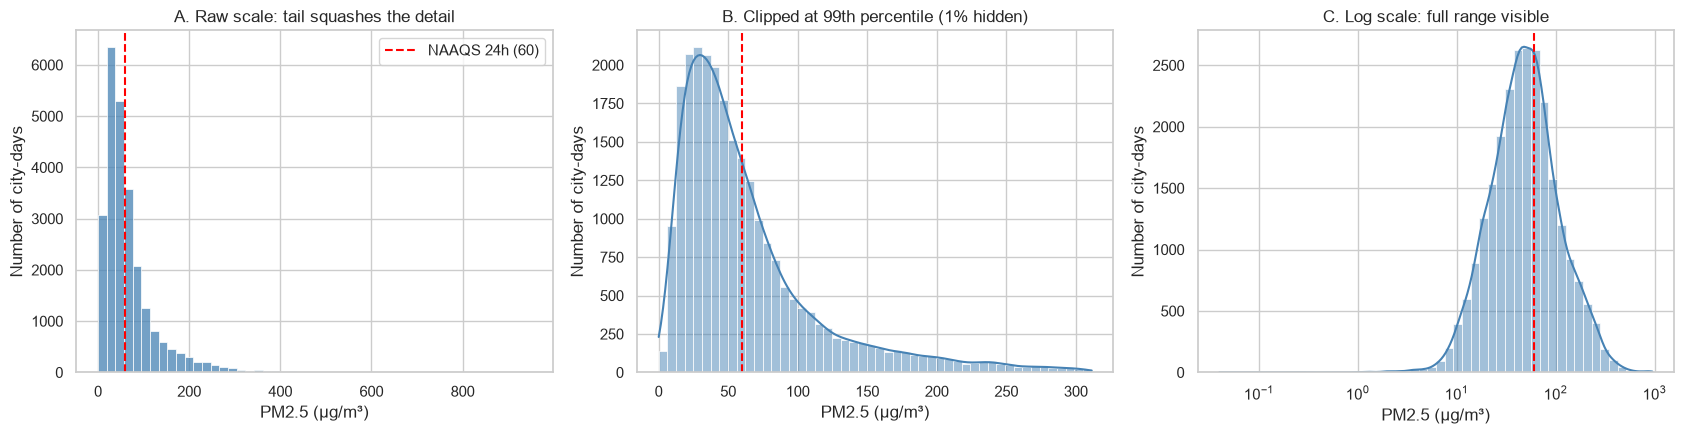

In [26]:
# Three versions of the PM2.5 histogram (all 26 cities pooled)
pm = df_clean["PM25"].dropna()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(pm, bins=50, ax=ax[0], color="steelblue")
ax[0].set_title("A. Raw scale: tail squashes the detail")

sns.histplot(pm[pm <= pm.quantile(.99)], bins=50, kde=True, ax=ax[1], color="steelblue")
ax[1].set_title("B. Clipped at 99th percentile (1% hidden)")

sns.histplot(pm, bins=50, log_scale=True, kde=True, ax=ax[2], color="steelblue")
ax[2].set_title("C. Log scale: full range visible")

for a in ax:
    a.axvline(NAAQS_PM25, color="red", ls="--", label="NAAQS 24h (60)")
    a.set_xlabel("PM2.5 (µg/m³)"); a.set_ylabel("Number of city-days")
ax[0].legend()
plt.tight_layout(); save("01_pm25_distribution"); plt.show()

In [27]:
# Skewness of every pollutant, raw vs after log(1 + x)
skew = pd.DataFrame({"skew": df_clean[pollutants].skew(),
                     "skew_log1p": np.log1p(df_clean[pollutants]).skew()}).round(2)
display(skew.sort_values("skew", ascending=False))

,skew,skew_log1p
Benzene,20.65,1.24
Toluene,11.53,0.49
CO,9.04,1.50
SO2,4.07,0.66
NH3,4.07,-0.08
NO,4.00,0.29
PM25,3.43,0.06
NOx,2.59,-0.83
NO2,2.47,-0.38
PM10,2.04,-0.57


### Insight Q1
- **Shape.** On the raw scale most days sit below about 100 µg/m³ and a thin tail runs out to nearly 950. On the log scale (panel C) the same data is close to a symmetric bell, so PM2.5 is approximately **log-normal**. The 60 µg/m³ line falls near the middle of the distribution, which means a large share of days is on each side of the standard.
- **Skewness proves it.** PM2.5 skew falls from **3.43 to 0.06** after the log transform.
- **The log transform is not universal.** It over-corrects O3 (1.33 → −1.00) and NOx (2.59 → −0.83), and CO (1.50) and Benzene (1.24) stay skewed. The log scale is therefore used for PM2.5 only, not applied blindly to every pollutant.

## Q2. How often does each city exceed the PM2.5 standard?
**Method.** An **ECDF** (empirical cumulative distribution function) shows, for any PM2.5 value on the x-axis, the share of days at or below it. Where a city's curve crosses the red line (60 µg/m³) the height is the share of days *within* the standard; one minus that height is the share of days above it. The table gives the exact percentages.

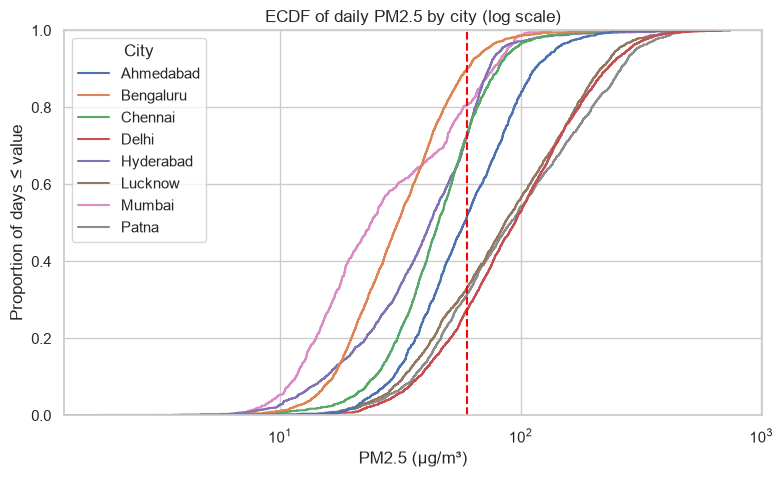

,valid_days,median,pct_days_above_60
City,,,
Delhi,2009,94.5,72.5
Patna,1553,91.0,68.3
Lucknow,1914,86.0,66.7
Ahmedabad,1406,58.4,48.0
Hyderabad,1901,42.0,27.5
Chennai,1900,45.5,26.7
Mumbai,789,23.8,19.3
Bengaluru,1879,30.8,10.0


In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.ecdfplot(data=df_core, x="PM25", hue="City", ax=ax)
ax.set_xscale("log"); ax.axvline(NAAQS_PM25, color="red", ls="--")
ax.set_title("ECDF of daily PM2.5 by city (log scale)")
ax.set_xlabel("PM2.5 (µg/m³)"); ax.set_ylabel("Proportion of days ≤ value")
save("02_pm25_ecdf_by_city"); plt.show()

(df_core.dropna(subset=["PM25"]).groupby("City", observed=True)["PM25"]
    .agg(valid_days="count", median="median",
         pct_days_above_60=lambda s: (s > NAAQS_PM25).mean() * 100)
    .round(1).sort_values("pct_days_above_60", ascending=False))

### Insight Q2
- **Three cities break the standard on roughly two days in three:** Delhi (72.5% of days with a reading), Patna (68.3%) and Lucknow (66.7%). Their medians (94.5, 91.0 and 86.0 µg/m³) are all above 60.
- **Ahmedabad is in the middle** (48.0%, median 58.4), **Hyderabad and Chennai** are near one day in four (27.5% and 26.7%), and **Bengaluru has the cleanest record** (10.0%).
- **Caution on Mumbai.** Its 19.3% is based on only 789 valid days out of 2,009 (39%). Q6 shows which months are missing, so treat Mumbai's figure as approximate.

## Q3. Which cities are the most polluted, and which are the most variable?
**Method.** A box plot per city (log scale), ordered from highest to lowest median. The box covers the middle 50% of days (25th to 75th percentile); the interquartile range (IQR) measures the typical spread.

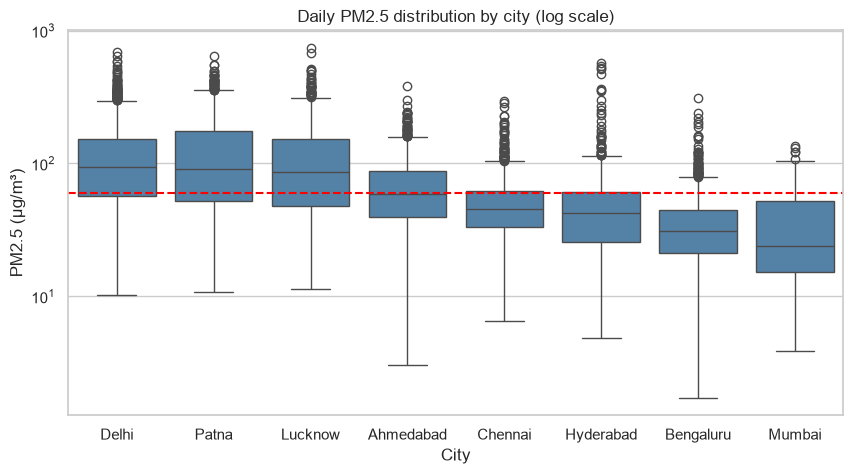

,25%,50%,75%,IQR
City,,,,
Delhi,57.1,94.5,153.0,95.9
Patna,51.8,91.0,174.2,122.4
Lucknow,47.5,86.0,153.3,105.8
Ahmedabad,39.4,58.4,87.1,47.6
Chennai,33.3,45.5,61.5,28.2
Hyderabad,25.8,42.0,61.4,35.6
Bengaluru,21.2,30.8,44.3,23.0
Mumbai,15.2,23.8,51.7,36.5


In [29]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_core, x="City", y="PM25", order=city_order, color="steelblue", ax=ax)
ax.set_yscale("log"); ax.axhline(NAAQS_PM25, color="red", ls="--")
ax.set_title("Daily PM2.5 distribution by city (log scale)")
ax.set_xlabel("City"); ax.set_ylabel("PM2.5 (µg/m³)")
save("03_pm25_box_by_city"); plt.show()

q = df_core.groupby("City", observed=True)["PM25"].describe(percentiles=[.25, .5, .75])[["25%", "50%", "75%"]]
q["IQR"] = q["75%"] - q["25%"]
q.loc[city_order].round(1)

### Insight Q3
- **Highest levels:** Delhi (median 94.5), Patna (91.0) and Lucknow (86.0).
- **Most variable:** **Patna** has the widest spread (IQR 122.4, 75th percentile 174.2), ahead of Lucknow (105.8) and Delhi (95.9). In these cities a "typical" day ranges from moderate to very polluted depending on the season.
- **Most stable:** Bengaluru (IQR 23.0) and Chennai (28.2).
- **Median and exceedance rank cities differently.** Mumbai has the *lowest median* (23.8) but Bengaluru has the *fewest days above 60* (10.0% vs 19.3%), because Mumbai's upper quartile (51.7) is higher than Bengaluru's (44.3). The two numbers answer different questions: the median describes a typical day, exceedance counts the bad days.

## Q4. How strongly does season change PM2.5?
**Method.** A violin plot per season (log scale, with quartile lines). Unlike a box plot, a violin shows whether a distribution has more than one peak. The table prints the median for each season.

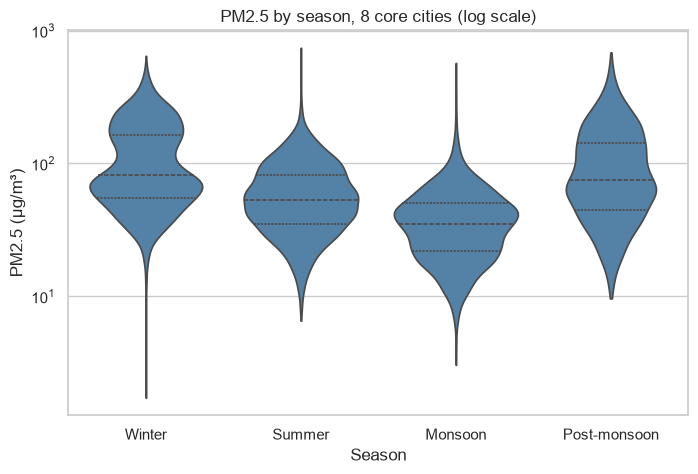

Season
Winter          81.1
Summer          53.1
Monsoon         34.9
Post-monsoon    75.6
Name: PM25, dtype: float64

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df_core, x="Season", y="PM25", order=season_order,
               cut=0, inner="quartile", log_scale=True, color="steelblue", ax=ax)
ax.set_title("PM2.5 by season, 8 core cities (log scale)")
ax.set_xlabel("Season"); ax.set_ylabel("PM2.5 (µg/m³)")
save("04_pm25_violin_by_season"); plt.show()

df_core.groupby("Season")["PM25"].median().reindex(season_order).round(1)

### Insight Q4
- **Winter is the worst season, monsoon the best:** median PM2.5 is **81.1** in winter, 75.6 post-monsoon, 53.1 in summer and **34.9 in monsoon**. Winter is about **2.3 times** monsoon.
- **Winter has two peaks** (one near 70–80 µg/m³ and one near 150–200 in the violin). A plausible reason is that the pooled data mixes northern cities (Delhi, Patna, Lucknow), which are very high in winter, with southern and coastal cities, which are not. Splitting the plot by city group would test this.
- **Pooling hides city differences.** The season medians combine cities with different amounts of data; Q11 separates them.

## Q5. What share of observed city-days falls in each AQI category?
**Method.** A bar chart of the percentage of city-days in each CPCB category, using colours that follow the usual AQI scale (green to dark red). Ahmedabad is excluded because its AQI was found to be unreliable (section 2.10).

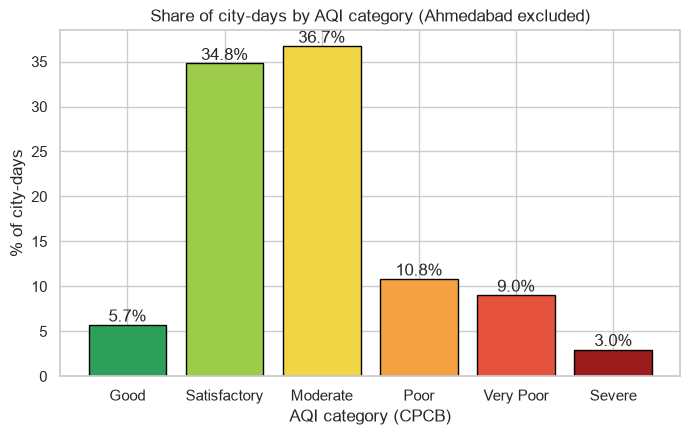

AQI_Category
Good             5.7
Satisfactory    34.8
Moderate        36.7
Poor            10.8
Very Poor        9.0
Severe           3.0
Name: proportion, dtype: float64


In [31]:
aqi_cat = df_clean.dropna(subset=["AQI_Category"])
share = aqi_cat["AQI_Category"].value_counts(normalize=True).reindex(order) * 100
colors = ["#2e9e5b", "#9ccc4a", "#f2d544", "#f5a142", "#e5533d", "#9b1c1c"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(order, share.values, color=colors, edgecolor="black")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_title("Share of city-days by AQI category (Ahmedabad excluded)")
ax.set_xlabel("AQI category (CPCB)"); ax.set_ylabel("% of city-days")
save("05_aqi_category_share"); plt.show()
print(share.round(1))

### Insight Q5
- Most city-days fall in the **Moderate** and **Satisfactory** categories; together they make up roughly two-thirds of all observations. The unhealthy categories (Poor, Very Poor and Severe) are a clear minority, but they are not rare.
- This pooled view mixes cities with very different records and says nothing about *where* the bad days occur. Q13 and Q14 break it down by city and season.

---
# Phase 4: Time series on the core cities (Q6–Q10)

**Goal.** Check how complete each city's record is over time, describe trends and seasonality, choose a sensible smoothing window, and compare the 2020 lockdown window with earlier years.

**Setup.** `mon` holds one row per city and month with the mean PM2.5 and the number of valid days. July 2020 is dropped because it contains a single day.

In [32]:
# Monthly mean PM2.5 and number of valid days for each core city
dfm = df_core[df_core["Date"] < "2020-07-01"]      # drop the single partial day in July 2020
LOCK_START, LOCK_END = pd.Timestamp("2020-03-25"), pd.Timestamp("2020-06-30")

mon = (dfm.groupby(["City", pd.Grouper(key="Date", freq="MS")], observed=True)["PM25"]
          .agg(mean="mean", valid="count").reset_index())
mon["coverage"] = mon["valid"] / mon["Date"].dt.days_in_month * 100

## Q6. How complete is the PM2.5 record for each city, month by month?
**Method.** A heatmap of the percentage of days in each month that have a PM2.5 reading (yellow = complete, dark = empty). The count below it is the number of "usable" months, defined as at least 20 valid days (67% of a month), out of 66.

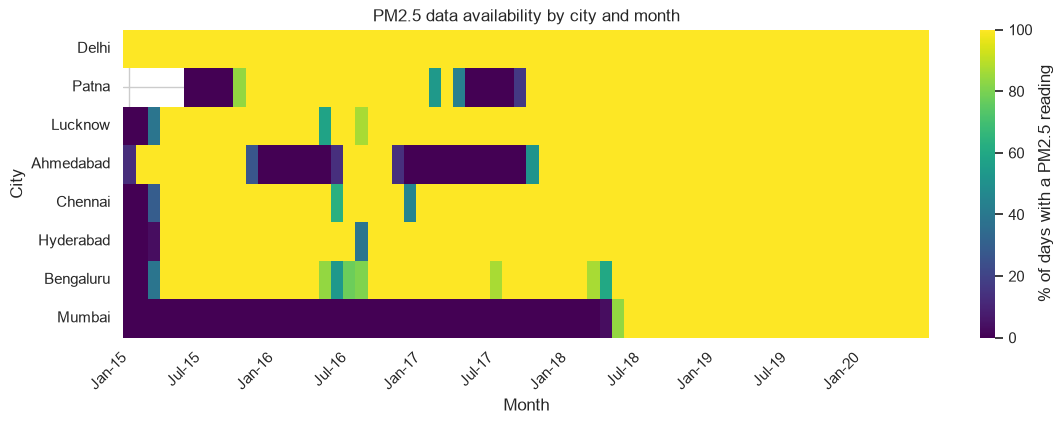

Usable months (>= 20 valid days) out of 66


City
Delhi        66
Patna        50
Lucknow      62
Ahmedabad    45
Chennai      61
Hyderabad    62
Bengaluru    61
Mumbai       26
dtype: int64

In [33]:
avail = mon.pivot(index="City", columns="Date", values="coverage").loc[city_order]
fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(avail, cmap="viridis", vmin=0, vmax=100, xticklabels=False,
            cbar_kws={"label": "% of days with a PM2.5 reading"}, ax=ax)
cols = avail.columns
ax.set_xticks(np.arange(0, len(cols), 6) + 0.5)
ax.set_xticklabels([c.strftime("%b-%y") for c in cols[::6]], rotation=45, ha="right")
ax.set_title("PM2.5 data availability by city and month")
ax.set_xlabel("Month"); ax.set_ylabel("City")
save("06_pm25_availability"); plt.show()

print("Usable months (>= 20 valid days) out of", avail.shape[1])
(avail >= 67).sum(axis=1)

### Insight Q6
- **Delhi is the only fully usable record:** 66 of 66 months. Lucknow and Hyderabad have 62, Chennai and Bengaluru 61, Patna 50, Ahmedabad 45 and **Mumbai only 26**.
- Mumbai's PM2.5 record begins in 2018 and Patna and Ahmedabad have missing stretches, so any statement about those cities rests on fewer months and carries more uncertainty.
- This chart decides how far each later result can be trusted. For example, only Delhi can be decomposed into trend and season without first filling gaps.

## Q7. How does monthly PM2.5 change over time, and is the lockdown dip visible?
**Method.** Small multiples (one panel per city, shared axes so levels are comparable). Months with fewer than 20 valid days are set to missing, so the line *breaks* instead of drawing a trend through months with almost no data. The grey band is the lockdown window. A table of yearly means follows, using only years with at least 200 valid days; 2020 contains only January to June, so it is not comparable with full years.

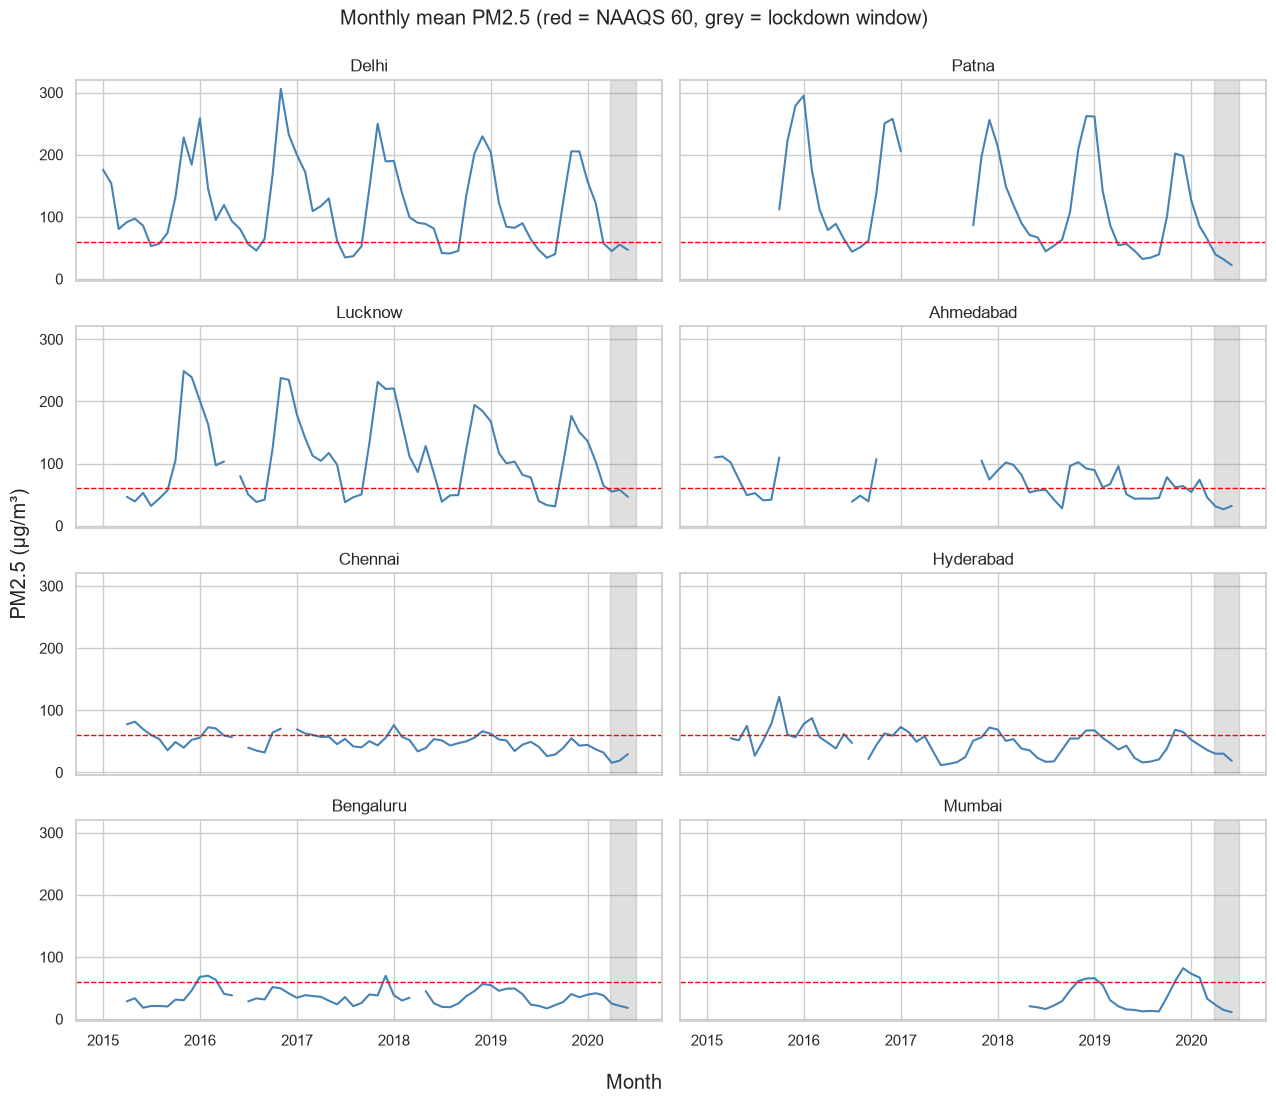

Date,2015,2016,2017,2018,2019,2020
City,,,,,,
Delhi,117.3,138.5,124.5,115.0,108.5,NaN
Patna,NaN,134.6,NaN,120.7,104.2,NaN
Lucknow,100.3,123.3,122.3,119.2,98.1,NaN
Ahmedabad,79.1,NaN,NaN,74.7,62.0,NaN
Chennai,60.4,55.4,53.1,52.1,43.9,NaN
Hyderabad,63.9,53.2,43.7,43.1,41.6,NaN
Bengaluru,28.7,46.6,35.8,34.8,35.4,NaN
Mumbai,NaN,NaN,NaN,35.2,34.7,NaN


In [34]:
mon.loc[mon["valid"] < 20, "mean"] = np.nan            # months with < 20 valid days are not trusted
monthly = mon.pivot(index="Date", columns="City", values="mean")

fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True, sharey=True)
for ax, city in zip(axes.ravel(), city_order):
    ax.plot(monthly.index, monthly[city], lw=1.5, color="steelblue")
    ax.axhline(NAAQS_PM25, color="red", ls="--", lw=1)
    ax.axvspan(LOCK_START, LOCK_END, color="grey", alpha=0.25)
    ax.set_title(city)
fig.suptitle("Monthly mean PM2.5 (red = NAAQS 60, grey = lockdown window)", y=0.995)
fig.supxlabel("Month"); fig.supylabel("PM2.5 (µg/m³)")
plt.tight_layout(); save("07_pm25_monthly_small_multiples"); plt.show()

# yearly means, only years with >= 200 valid days
yr = dfm.groupby(["City", dfm["Date"].dt.year], observed=True)["PM25"].agg(["mean", "count"])
yr.loc[yr["count"] < 200, "mean"] = np.nan
yr["mean"].unstack().round(1).loc[city_order]        # 2020 = Jan-Jun only, so not comparable

### Insight Q7
- **Every northern city has a sharp winter peak each year.** Delhi, Patna and Lucknow reach monthly means of roughly 200–300 µg/m³ in winter and fall to roughly 30–60 in the monsoon. Chennai, Hyderabad, Bengaluru and Mumbai stay mostly between about 15 and 80 µg/m³, with only occasional higher months (Hyderabad reaches about 120 in 2015).
- **Most cities improved after 2016.** Delhi's yearly mean was 138.5 in 2016 and 108.5 in 2019, Patna 134.6 → 104.2, Lucknow 123.3 → 98.1, Chennai 60.4 (2015) → 43.9 and Hyderabad 63.9 (2015) → 41.6.
- **Not every change is a trend.** Bengaluru's 2015 mean (28.7) is far below 2016 (46.6), which is more likely a data artefact than a real jump.
- **The dip in the lockdown window must be read carefully.** April–June is naturally a cleaner period (summer into monsoon), so a lower value in 2020 is expected even without a lockdown. Q10 therefore compares the *same calendar dates* in other years.

## Q8. Which smoothing window shows Delhi's pattern best?
**Method.** Delhi is used because it has a reading on every day, so no values need to be filled. The daily series is drawn with a 7-day and a 30-day rolling mean. "Smoothness" is the average absolute day-to-day change (lower = smoother).

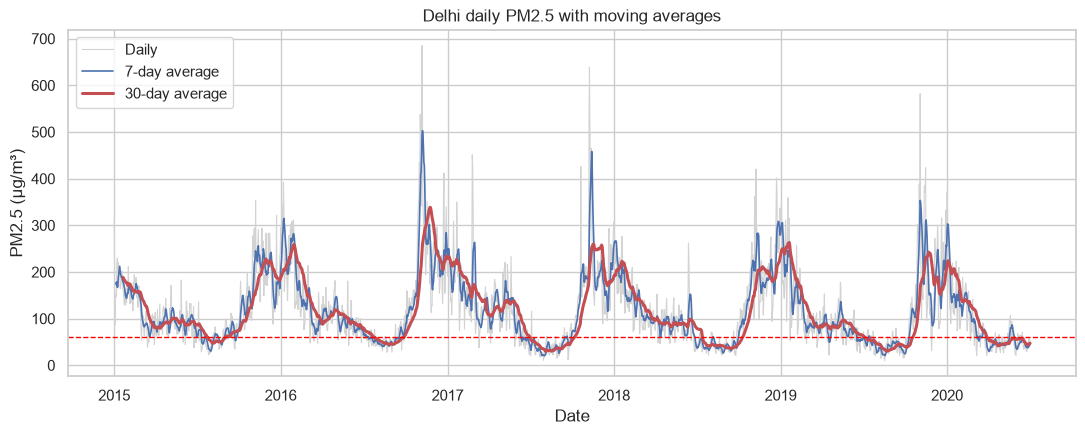

daily     26.13
7-day      6.69
30-day     2.00
dtype: float64

In [35]:
delhi = df_core.loc[df_core["City"] == "Delhi"].set_index("Date")["PM25"].asfreq("D")
r7  = delhi.rolling(7,  min_periods=5).mean()
r30 = delhi.rolling(30, min_periods=20).mean()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(delhi, color="lightgrey", lw=0.8, label="Daily")
ax.plot(r7,  lw=1.2, label="7-day average")
ax.plot(r30, lw=2.2, color="C3", label="30-day average")
ax.axhline(NAAQS_PM25, color="red", ls="--", lw=1)
ax.set_title("Delhi daily PM2.5 with moving averages")
ax.set_xlabel("Date"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend()
save("08_delhi_rolling"); plt.show()

# smoothness = average day-to-day change (lower = smoother)
pd.Series({"daily": delhi.diff().abs().mean(), "7-day": r7.diff().abs().mean(),
           "30-day": r30.diff().abs().mean()}).round(2)

### Insight Q8
- Average day-to-day change is **26.1 µg/m³** for the daily series, **6.7** for the 7-day mean and **2.0** for the 30-day mean. The 30-day average is about 13 times smoother than the raw data.
- **The 7-day mean keeps individual pollution episodes** (multi-day smog events) visible, while the **30-day mean shows the seasonal rhythm** and the slow decline over the years. Use the 7-day window to study episodes and the 30-day window to show the seasonal pattern.

## Q9. Is Delhi's seasonality additive or multiplicative?
**Method.** Monthly mean PM2.5 for Delhi (66 months, no missing values) is decomposed into trend, seasonal and residual components with a 12-month period, once with an **additive** model (observed = trend + seasonal + residual) and once with a **multiplicative** one (observed = trend × seasonal × residual). To choose, the size of the residual is correlated with the level of the trend: a good model leaves residuals that do **not** grow as the level grows, so a correlation closer to 0 means a better fit.

Months: 66 | NaNs: 0


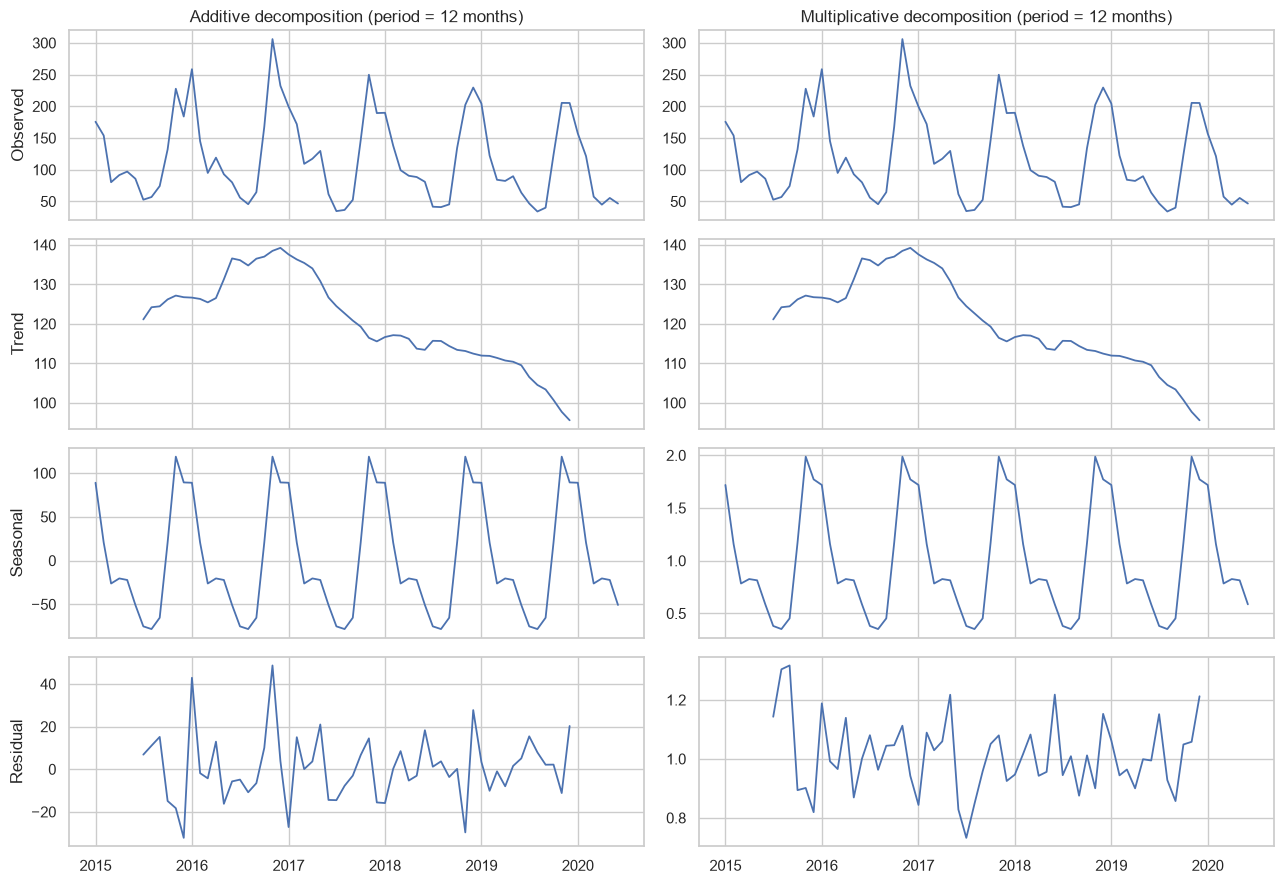

additive       |resid| vs trend: 0.2
multiplicative |resid-1| vs trend: 0.04
Date
1      89.0
2      20.5
3     -26.2
4     -20.4
5     -22.2
6     -50.8
7     -75.2
8     -78.3
9     -65.4
10     20.8
11    118.8
12     89.4
Name: seasonal, dtype: float64


In [36]:
d_m = monthly["Delhi"]
print("Months:", len(d_m), "| NaNs:", d_m.isna().sum())     # must be 0 for decomposition
add = seasonal_decompose(d_m, model="additive", period=12)
mul = seasonal_decompose(d_m, model="multiplicative", period=12)

fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
for j, (name, res) in enumerate([("Additive", add), ("Multiplicative", mul)]):
    for i, (lab, comp) in enumerate([("Observed", res.observed), ("Trend", res.trend),
                                     ("Seasonal", res.seasonal), ("Residual", res.resid)]):
        axes[i, j].plot(comp, lw=1.3)
        axes[i, 0].set_ylabel(lab)
    axes[0, j].set_title(f"{name} decomposition (period = 12 months)")
plt.tight_layout(); save("09_delhi_decomposition"); plt.show()

# does the residual grow with the trend? (closer to 0 = model fits better)
t = add.trend.dropna()
print("additive       |resid| vs trend:", round(add.resid.dropna().abs().corr(t), 2))
print("multiplicative |resid-1| vs trend:", round((mul.resid.dropna() - 1).abs().corr(t), 2))
print(add.seasonal.groupby(add.seasonal.index.month).first().round(1))   # monthly seasonal effect

### Insight Q9
- **Multiplicative fits better.** The residual–trend correlation is **0.04 for the multiplicative model and 0.20 for the additive one**: Delhi's seasonal swings grow in proportion to the overall pollution level.
- **Peak and trough.** In the additive seasonal component, **November (+118.8 µg/m³)**, December (+89.4) and January (+89.0) are the highest months and **August (−78.3)** and July (−75.2) the lowest, a peak-to-trough range of about 197 µg/m³. In the multiplicative model November is about twice Delhi's annual level and August about 0.4 times it.
- **The worst month is November, not December or January.** The peak falls in the post-monsoon period. This timing is commonly linked to crop-residue burning, festival emissions and cooler, stiller air, but this dataset cannot show the cause.
- **Trend.** The trend component rises to about 139 µg/m³ around the end of 2016 and then falls steadily to about 96 by late 2019, roughly 30% lower.

## Q10. How much did PM2.5 and NO2 change in the lockdown window compared with earlier years?
**Method.** For each city the mean over 25 Mar–30 Jun 2020 is compared with the mean over **the same calendar dates** in earlier years, which removes the effect of season. A year counts only if it has at least 60 valid days out of the 98-day window.

Two baselines are used because pollution was already falling before 2020:
- **Main baseline:** 2016–2019, requiring at least two usable baseline years.
- **Sensitivity check:** 2019 only, which isolates the most recent year.

If the two baselines give a similar answer, the finding is robust. NO2 is shown next to PM2.5 because it is mainly a traffic tracer, while PM2.5 also comes from dust, burning and weather.

PM2.5: main baseline 2016-19 (at least 2 baseline years)


,baseline_years,baseline,lockdown_2020,change_pct
Ahmedabad,2.0,67.1,29.8,-55.6
Bengaluru,4.0,36.4,21.8,-40.1
Chennai,4.0,48.4,21.8,-54.9
Delhi,4.0,92.1,47.9,-48.0
Hyderabad,4.0,39.1,26.9,-31.1
Lucknow,4.0,96.2,52.7,-45.2
Patna,3.0,70.8,32.3,-54.4


PM2.5: sensitivity check, baseline 2019 only


,baseline_years,baseline,lockdown_2020,change_pct
Ahmedabad,1.0,64.9,29.8,-54.1
Bengaluru,1.0,38.9,21.8,-43.9
Chennai,1.0,42.6,21.8,-48.8
Delhi,1.0,79.4,47.9,-39.6
Hyderabad,1.0,35.8,26.9,-24.7
Lucknow,1.0,88.9,52.7,-40.7
Mumbai,1.0,18.1,17.0,-6.3
Patna,1.0,53.6,32.3,-39.7


NO2: main baseline 2016-19 (at least 2 baseline years)


,baseline_years,baseline,lockdown_2020,change_pct
Ahmedabad,2.0,72.9,24.3,-66.7
Bengaluru,4.0,26.6,13.5,-49.3
Chennai,4.0,17.1,9.3,-45.7
Delhi,4.0,54.1,22.8,-57.8
Hyderabad,4.0,28.9,22.9,-20.7
Lucknow,4.0,36.9,14.7,-60.2
Patna,3.0,32.1,24.4,-24.0


NO2: sensitivity check, baseline 2019 only


,baseline_years,baseline,lockdown_2020,change_pct
Ahmedabad,1.0,93.5,24.3,-74.0
Bengaluru,1.0,27.9,13.5,-51.8
Chennai,1.0,16.7,9.3,-44.5
Delhi,1.0,46.4,22.8,-50.8
Hyderabad,1.0,28.2,22.9,-18.8
Lucknow,1.0,32.2,14.7,-54.3
Mumbai,1.0,16.3,9.1,-43.9
Patna,1.0,33.2,24.4,-26.5


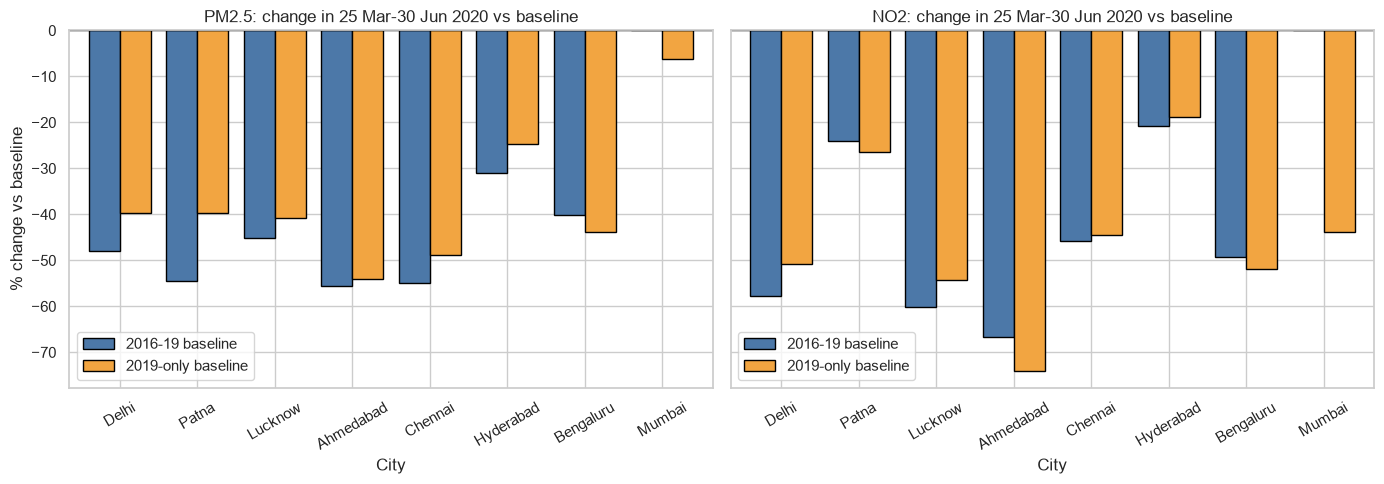

In [37]:
def lockdown_change(df, pol, base_years, min_days=60, min_base=1):
    """% change of the 25 Mar-30 Jun 2020 mean vs the mean of the same calendar window in base_years."""
    out = {}
    for city, g in df.groupby("City", observed=True):
        s = g.set_index("Date")[pol].dropna()
        md = s.index.strftime("%m-%d")
        s = s[(md >= "03-25") & (md <= "06-30")]          # same calendar window every year (98 days)
        yr = s.groupby(s.index.year).agg(["mean", "count"])
        yr = yr[yr["count"] >= min_days]                   # a year counts only with >= 60 valid days
        base = yr.loc[yr.index.isin(list(base_years)), "mean"]
        if 2020 in yr.index and len(base) >= min_base:
            out[city] = {"baseline_years": len(base), "baseline": base.mean(),
                         "lockdown_2020": yr.loc[2020, "mean"],
                         "change_pct": (yr.loc[2020, "mean"] / base.mean() - 1) * 100}
    return pd.DataFrame(out).T.round(1)

tables = {}
for pol, label in [("PM25", "PM2.5"), ("NO2", "NO2")]:
    main = lockdown_change(df_core, pol, base_years=range(2016, 2020), min_base=2)
    sens = lockdown_change(df_core, pol, base_years=[2019], min_base=1)
    print(f"{label}: main baseline 2016-19 (at least 2 baseline years)"); display(main)
    print(f"{label}: sensitivity check, baseline 2019 only"); display(sens)
    tables[label] = pd.DataFrame({"2016-19 baseline": main["change_pct"],
                                  "2019-only baseline": sens["change_pct"]}).reindex(list(city_order))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, label in zip(axes, tables):
    tables[label].plot(kind="bar", ax=ax, edgecolor="black", width=0.8, color=["#4c78a8", "#f2a541"])
    ax.axhline(0, color="black", lw=1)
    ax.set_title(f"{label}: change in 25 Mar-30 Jun 2020 vs baseline")
    ax.set_xlabel("City"); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("% change vs baseline")
plt.tight_layout(); save("10_lockdown_change"); plt.show()

### Insight Q10
| City | PM2.5 vs 2016–19 | PM2.5 vs 2019 only | NO2 vs 2016–19 | NO2 vs 2019 only |
|---|---|---|---|---|
| Delhi | −48.0% | −39.6% | −57.8% | −50.8% |
| Lucknow | −45.2% | −40.7% | −60.2% | −54.3% |
| Patna | −54.4% | −39.7% | −24.0% | −26.5% |
| Hyderabad | −31.1% | −24.7% | −20.7% | −18.8% |
| Chennai | −54.9% | −48.8% | −45.7% | −44.5% |
| Bengaluru | −40.1% | −43.9% | −49.3% | −51.8% |
| Ahmedabad | −55.6% | −54.1% | −66.7% | −74.0% |
| Mumbai | not enough baseline | −6.3% | not enough baseline | −43.9% |

- **Every city was lower in the 2020 window under both baselines**, so the direction is robust. PM2.5 was **31–56% lower** than the 2016–19 average and **25–54% lower** than 2019 alone (Mumbai excluded).
- **The size of the drop depends on the baseline.** Against 2019 alone the drop is smaller in most cities (Patna −54% → −40%, Delhi −48% → −40%) because pollution was already falling. Bengaluru is the exception. Report a **range**, not one number.
- **NO2 did not always fall more than PM2.5.** It fell more in 4 of the 7 cities (Ahmedabad, Bengaluru, Delhi, Lucknow) and less in Chennai, Hyderabad and Patna (Patna: NO2 −24% against PM2.5 −54%). The expectation that NO2 would show the clearer lockdown effect is therefore only partly supported.
- **Confidence is lower for some cities.** Ahmedabad's 2016–19 baseline has only 2 usable years and Patna's 3; Ahmedabad's record also has other data problems (sections 2.7 and 2.10). Mumbai has a baseline of only 2019 and its PM2.5 change (−6.3%) is far smaller than its NO2 change (−43.9%), with just 39% PM2.5 coverage.
- **These are observed differences, not proof that the lockdown caused them.** Weather, rainfall and other year-to-year changes also differ between years.

---
# Phase 5: Comparison charts (Q11–Q15)

**Goal.** Compare cities, seasons and years with grouped, stacked and normalized bar charts and subplot layouts, and judge which layout communicates each comparison best.

**Setup.** A city–season cell is plotted only if it has at least `MIN_DAYS = 30` valid days, because a median over a handful of days would not be a fair comparison. `aqi_core` contains the core-city rows that have an AQI category (Ahmedabad's are excluded, see section 2.10).

In [38]:
# Setup for the comparison charts
from matplotlib.patches import Patch
MIN_DAYS = 30                                   # a city-season cell needs >= 30 valid days to be plotted
aqi_core = df_core.dropna(subset=["AQI_Category"])
season_colors = ["#4c78a8", "#f2a541", "#59a14f", "#b07aa1"]   # Winter, Summer, Monsoon, Post-monsoon

## Q11. How does each city's median PM2.5 change by season? (grouped bar)
**Method.** Median PM2.5 for every city–season pair, drawn as grouped bars (one group per city, one bar per season). The median is used instead of the mean because PM2.5 is strongly skewed.

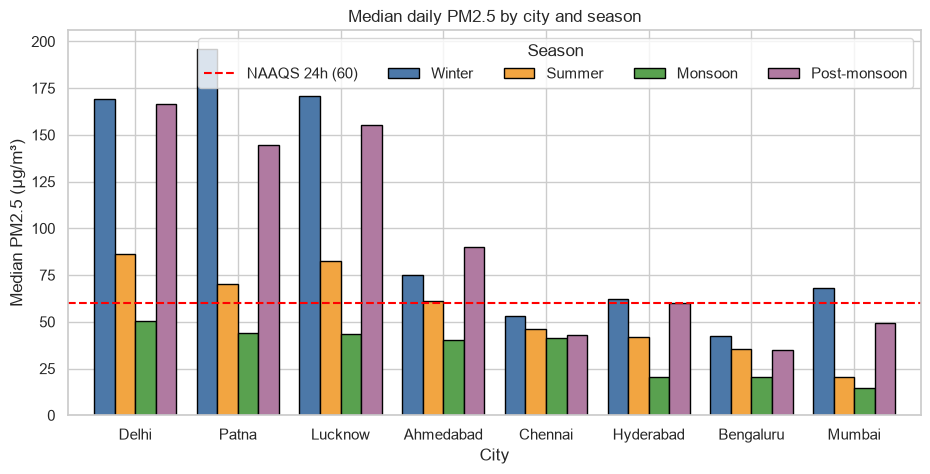

Season,Winter,Summer,Monsoon,Post-monsoon
City,,,,
Delhi,169.0,86.3,50.5,166.4
Patna,196.2,70.5,43.9,144.7
Lucknow,170.8,82.3,43.6,155.1
Ahmedabad,75.1,61.1,40.2,90.1
Chennai,52.9,46.2,41.2,43.2
Hyderabad,62.4,41.7,20.5,59.8
Bengaluru,42.7,35.7,20.4,35.0
Mumbai,68.1,20.6,14.6,49.5


In [39]:
pt  = df_core.pivot_table(index="City", columns="Season", values="PM25", aggfunc="median", observed=True)
cnt = df_core.pivot_table(index="City", columns="Season", values="PM25", aggfunc="count",  observed=True)
pt = pt.where(cnt >= MIN_DAYS).loc[city_order, season_order]

ax = pt.plot(kind="bar", figsize=(11, 5), width=0.8, edgecolor="black", color=season_colors)
ax.axhline(NAAQS_PM25, color="red", ls="--", label="NAAQS 24h (60)")
ax.set_title("Median daily PM2.5 by city and season")
ax.set_xlabel("City"); ax.set_ylabel("Median PM2.5 (µg/m³)")
plt.xticks(rotation=0); ax.legend(title="Season", ncol=5)
save("11_pm25_grouped_city_season"); plt.show()
display(pt.round(1))

### Insight Q11
- **Monsoon is the cleanest season in all 8 cities**, and **winter or post-monsoon is the dirtiest in all 8** (winter in seven of them).
- **Patna has the highest winter median (196.2 µg/m³)**, ahead of Lucknow (170.8) and Delhi (169.0). All three are far above the 60 µg/m³ standard in winter and post-monsoon (Delhi 166.4, Lucknow 155.1, Patna 144.7).
- **Size of the seasonal swing (winter ÷ monsoon):** Patna 4.5×, Lucknow 3.9×, Delhi 3.3×, Hyderabad 3.0×, Bengaluru 2.1×, Ahmedabad 1.9×, **Chennai only 1.3×** (41.2 to 52.9 µg/m³). Chennai's seasonal pattern is nearly flat.
- **Ahmedabad is the exception:** its highest median is post-monsoon (90.1), above winter (75.1). Its record has gaps (45 usable months), so this should be read with caution.
- **Mumbai's winter-to-monsoon ratio (4.7×)** comes from the shortest record (39% of days), so it is the least certain of the ratios.

## Q12. Which cities have the most days in each AQI category? (stacked bar, absolute counts)
**Method.** For each core city, the number of days in each AQI category is stacked into one bar. Ahmedabad has no valid AQI days after the exclusion and appears empty.

> **Second chart critique.** This chart can mislead. A taller bar can mean *more pollution* or simply *more days with a reading*; the two cannot be separated in absolute counts. The next chart removes the problem.

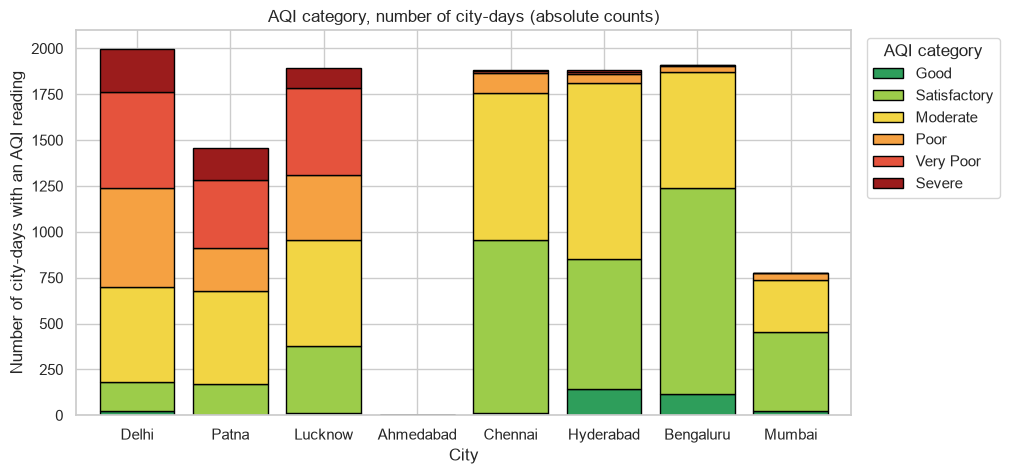

In [40]:
ct = (pd.crosstab(aqi_core["City"], aqi_core["AQI_Category"])
        .reindex(index=city_order, columns=order, fill_value=0))
ax = ct.plot(kind="bar", stacked=True, figsize=(10, 5), color=colors, edgecolor="black", width=0.8)
ax.set_title("AQI category, number of city-days (absolute counts)")
ax.set_xlabel("City"); ax.set_ylabel("Number of city-days with an AQI reading")
plt.xticks(rotation=0); ax.legend(title="AQI category", bbox_to_anchor=(1.01, 1), loc="upper left")
save("12_aqi_stacked_absolute"); plt.show()

### Insight Q12
Bar heights differ mainly because cities have different numbers of AQI readings, not because their air differs by the same amount. Absolute counts are useful for seeing *how much data exists* per city, but they should not be used to rank cities by pollution. Q13 fixes this by normalizing.

## Q13. Which cities have the worst AQI mix, regardless of how many days they have? (normalized stacked bar)
**Method.** Each bar is rescaled to 100%, so it shows the *composition* of a city's days. The number of days behind each bar (`n`) is printed under the city name. Absolute counts answer "how much data?" and percentages answer "how bad is a typical day?"; neither replaces the other.

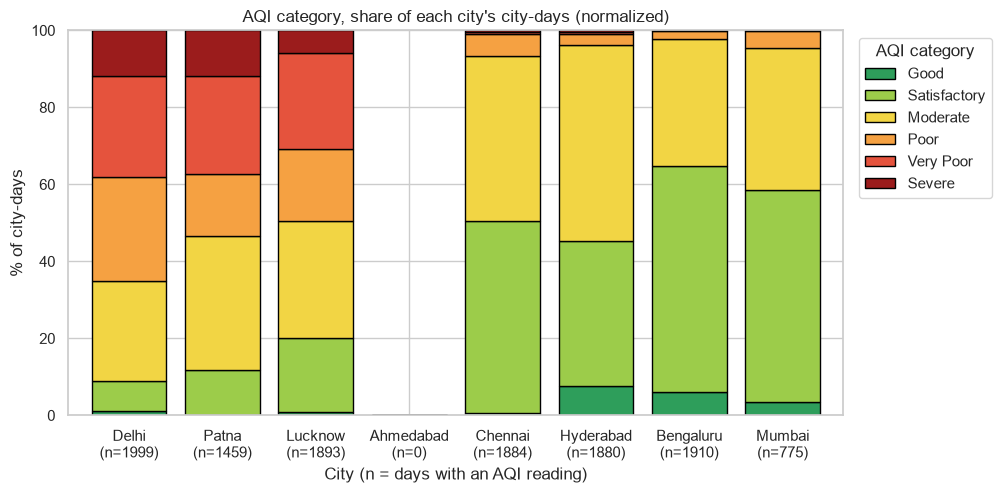

% of days Poor or worse:
City
Delhi        65.1
Patna        53.5
Lucknow      49.4
Ahmedabad     NaN
Chennai       6.7
Hyderabad     3.8
Bengaluru     2.1
Mumbai        4.6
dtype: float64


In [41]:
n = ct.sum(axis=1)
pct = ct.div(n, axis=0) * 100
ax = pct.plot(kind="bar", stacked=True, figsize=(10, 5), color=colors, edgecolor="black", width=0.8)
ax.set_xticklabels([f"{c}\n(n={n[c]})" for c in pct.index], rotation=0)
ax.set_title("AQI category, share of each city's city-days (normalized)")
ax.set_xlabel("City (n = days with an AQI reading)"); ax.set_ylabel("% of city-days")
ax.legend(title="AQI category", bbox_to_anchor=(1.01, 1), loc="upper left")
save("13_aqi_stacked_normalized"); plt.show()
print("% of days Poor or worse:")
print(pct[["Poor", "Very Poor", "Severe"]].sum(axis=1, min_count=1).round(1))

### Insight Q13
- **Share of days rated Poor or worse:** Delhi **65.1%**, Patna **53.5%**, Lucknow **49.4%**, against Chennai 6.7%, Mumbai 4.6%, Hyderabad 3.8% and Bengaluru 2.1%. The cities fall into two clearly separated groups: a northern group with roughly half or more of all days unhealthy, and a southern/western group below 7%.
- **Ahmedabad shows n = 0** because its AQI series was excluded (section 2.10). Before the exclusion it appeared as the worst city (81.9% Poor or worse), a result that contradicted its own PM2.5 levels and was the clue that led to the data-quality audit.

## Q14. Does the city ranking hold in every season? (subplots)
**Method.** One panel per season with a shared y-axis and the same colours, so cities can be compared inside a panel and seasons side by side without switching between figures. A city–season bar is left empty if it has fewer than 30 AQI days.

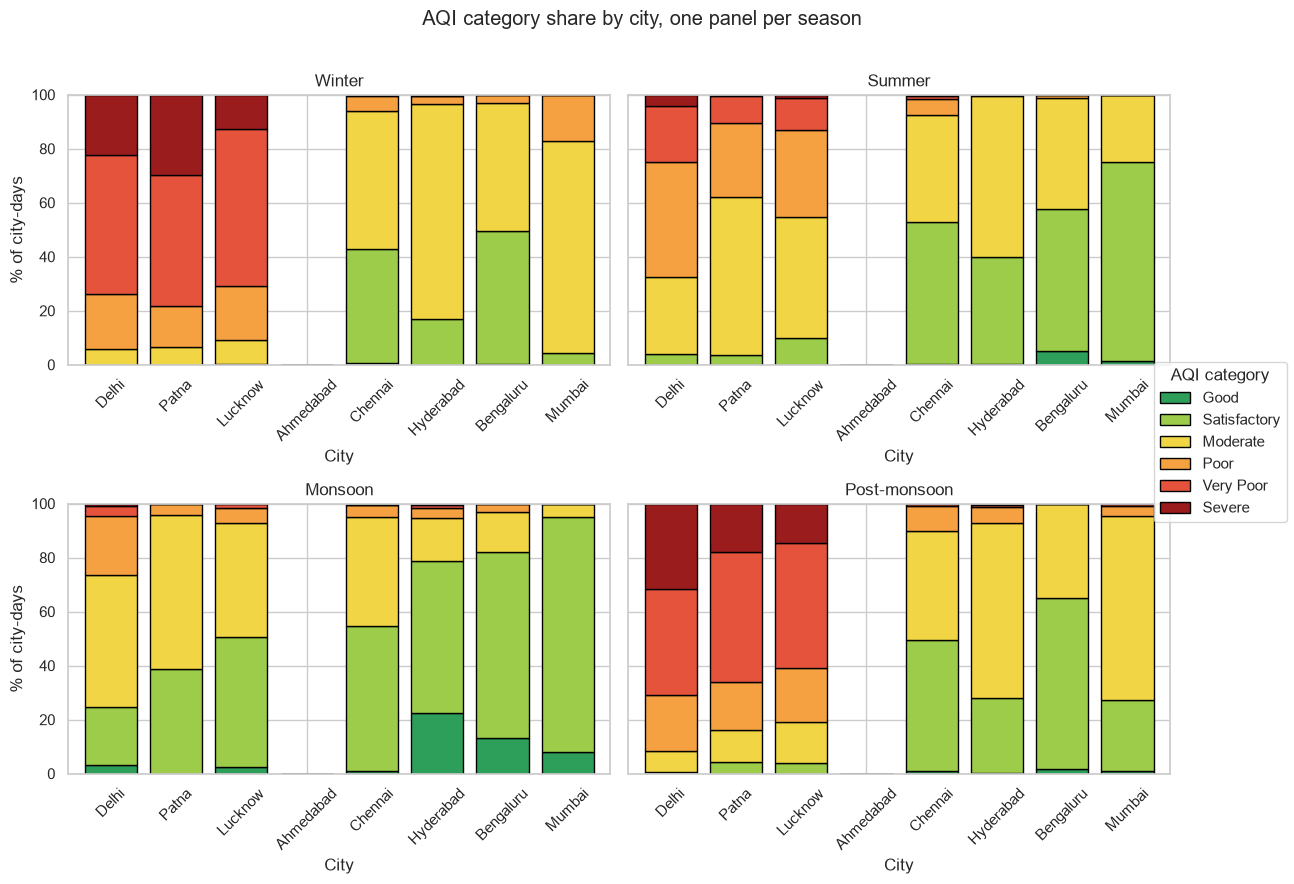

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, s in zip(axes.ravel(), season_order):
    sub = aqi_core[aqi_core["Season"] == s]
    c = (pd.crosstab(sub["City"], sub["AQI_Category"])
           .reindex(index=city_order, columns=order, fill_value=0))
    nn = c.sum(axis=1)
    p = c.div(nn.where(nn >= MIN_DAYS), axis=0) * 100        # NaN row = too little data, bar left empty
    p.plot(kind="bar", stacked=True, color=colors, edgecolor="black", width=0.8, ax=ax, legend=False)
    ax.set_title(s); ax.set_xlabel("City"); ax.set_ylabel("% of city-days")
    ax.tick_params(axis="x", rotation=45)
fig.legend(handles=[Patch(facecolor=c, edgecolor="black", label=l) for c, l in zip(colors, order)],
           title="AQI category", loc="center right")
fig.suptitle("AQI category share by city, one panel per season")
plt.tight_layout(rect=[0, 0, 0.92, 0.97]); save("14_aqi_share_by_season_panels"); plt.show()

### Insight Q14
- **The north–south gap holds in every season.** In winter, summer and post-monsoon, Delhi, Patna and Lucknow have the largest Poor, Very Poor and Severe shares. The gap is widest in winter and post-monsoon. In the monsoon most cities are mostly Satisfactory or Moderate and only Delhi still has a noticeable Poor share.
- **The southern cities and Mumbai have almost no Poor-or-worse days in any season**, except for a visible Poor share in Mumbai's winter. Hyderabad, Bengaluru and Mumbai have the largest shares of "Good" days in the monsoon.
- **The panel layout makes this easy to read.** A single stacked chart pooled over seasons (Q13) would hide that the problem is concentrated in winter and post-monsoon.

## Q15. Which cities improved from year to year? (grouped bar by year)
**Method.** Yearly mean PM2.5 per city, one bar per year, using only years with at least 200 valid days. 2020 is excluded because it covers January to June only. The printed table shows the percentage change from each city's first full year to 2019.

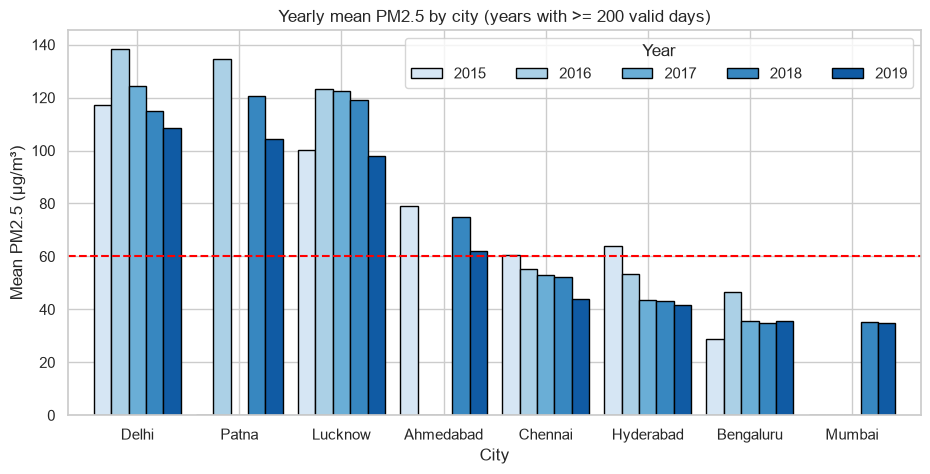

City
Delhi        -8.0
Patna       -23.0
Lucknow      -2.0
Ahmedabad   -22.0
Chennai     -27.0
Hyderabad   -35.0
Bengaluru    23.0
Mumbai       -1.0
Name: % change, first full year to 2019, dtype: float64

In [43]:
yr = dfm.groupby(["City", dfm["Date"].dt.year], observed=True)["PM25"].agg(["mean", "count"])
yr.loc[yr["count"] < 200, "mean"] = np.nan
yrm = yr["mean"].unstack().drop(columns=[2020], errors="ignore").loc[city_order]
ax = yrm.plot(kind="bar", figsize=(11, 5), width=0.85, edgecolor="black",
              color=sns.color_palette("Blues", len(yrm.columns)))
ax.axhline(NAAQS_PM25, color="red", ls="--")
ax.set_title("Yearly mean PM2.5 by city (years with >= 200 valid days)")
ax.set_xlabel("City"); ax.set_ylabel("Mean PM2.5 (µg/m³)")
plt.xticks(rotation=0); ax.legend(title="Year", ncol=5)
save("15_pm25_yearly_grouped"); plt.show()

first = yrm.bfill(axis=1).iloc[:, 0]                          # first available full year
display(((yrm[2019] / first - 1) * 100).round(0).rename("% change, first full year to 2019"))

### Insight Q15
- **Hyderabad (−35%), Chennai (−27%), Patna (−23%) and Ahmedabad (−22%) improved most** between their first full year and 2019, while Delhi (−8%), Lucknow (−2%) and Mumbai (−1%) barely changed.
- **The windows are not comparable.** The "first full year" differs by city: Patna's is 2016, Ahmedabad's and Chennai's 2015, and **Mumbai's is 2018, so its −1% compares only two years**. Bengaluru's **+23%** is an artefact of a very low 2015 value (28.7); from 2016 (46.6) to 2019 (35.4) it fell by about 24%. A fair comparison would use the same window (2016 to 2019) wherever it is available.
- **Delhi's yearly means** (138.5 in 2016, 108.5 in 2019) show a fall of about 22% from its 2016 peak, larger than the −8% measured from 2015.

---
# Phase 6: Relationships between pollutants (Q16–Q19)

**Goal.** Show how pollutants relate to each other, whether the relationship differs by city and season, and how the whole PM2.5 distribution shifts between seasons.

**Techniques.** Multivariate scatter (colour, marker, size, transparency), correlation heatmap, faceting, KDE.

**Why Spearman correlation.** Pollutant values are heavily skewed (PM2.5 skew is 3.43), and a few extreme days would dominate a Pearson correlation. Spearman correlation uses ranks, so extreme values matter much less.

## Q16. How do PM2.5 and NO2 relate, and does season or city change it? (multivariate scatter)
**Method.** One chart encodes five variables: x = NO2, y = PM2.5, **colour = season**, **marker = city** (Delhi, Chennai, Mumbai: high, middle and low pollution) and **size = O3**. Both axes use a log scale and the points are semi-transparent (alpha 0.45) because thousands of points overlap. The red line is the 60 µg/m³ standard.

City
Chennai    1892
Delhi      1928
Mumbai      759
dtype: int64


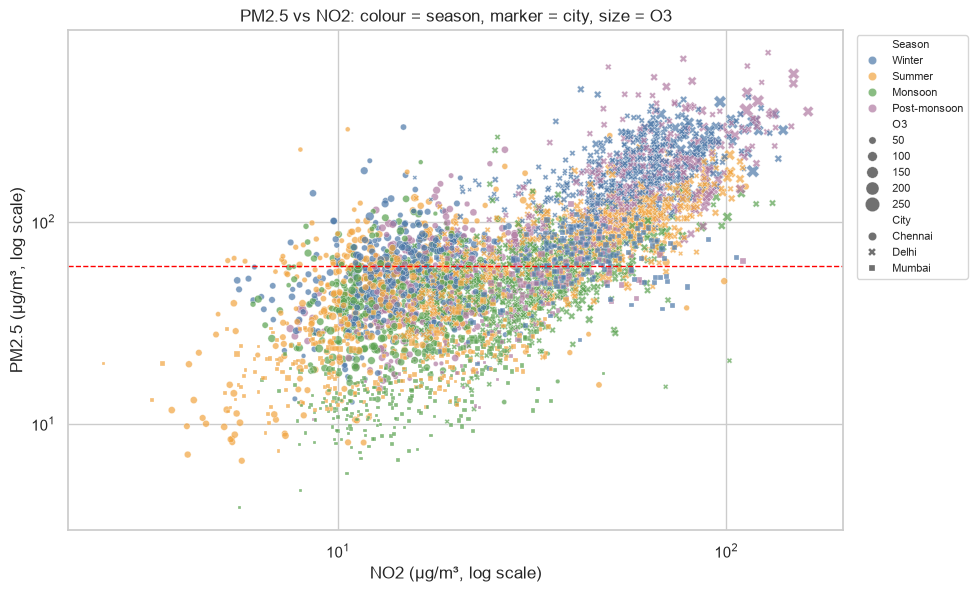

In [44]:
sub = df_core[df_core["City"].isin(["Delhi", "Mumbai", "Chennai"])].dropna(subset=["PM25", "NO2", "O3"]).copy()
sub["City"] = sub["City"].astype(str)
print(sub.groupby("City").size())
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=sub, x="NO2", y="PM25", hue="Season", hue_order=season_order,
                palette=dict(zip(season_order, season_colors)), style="City",
                size="O3", sizes=(8, 110), alpha=0.7, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(NAAQS_PM25, color="red", ls="--", lw=1)
ax.set_title("PM2.5 vs NO2: colour = season, marker = city, size = O3")
ax.set_xlabel("NO2 (µg/m³, log scale)"); ax.set_ylabel("PM2.5 (µg/m³, log scale)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
save("16_pm25_no2_multivariate"); plt.show()

### Insight Q16
- **PM2.5 rises with NO2** across all three cities (Delhi 1,928 days, Chennai 1,892, Mumbai 759).
- **City separates the groups.** Delhi sits in the upper right (high NO2 and high PM2.5), Mumbai in the lower left, and Chennai in between.
- **Season separates points within a city.** Winter and post-monsoon points lie at the top and right of each cloud, monsoon points at the bottom. Part of the PM2.5–NO2 relationship is therefore a shared seasonal effect, since both pollutants rise when winter air is still and cold. This is why the colour encoding matters.
- **Limitation.** Marker size (O3) is hard to read when many points overlap; it is the weakest of the five encodings.

## Q17. Which pollutants move together? (correlation heatmap)
**Method.** A Spearman correlation matrix for all eleven pollutants over the 8 core cities. The upper triangle is hidden because it repeats the lower one. Below the chart, the correlation of PM2.5 with every other pollutant is printed, followed by the PM2.5–NO2 correlation for each city separately.

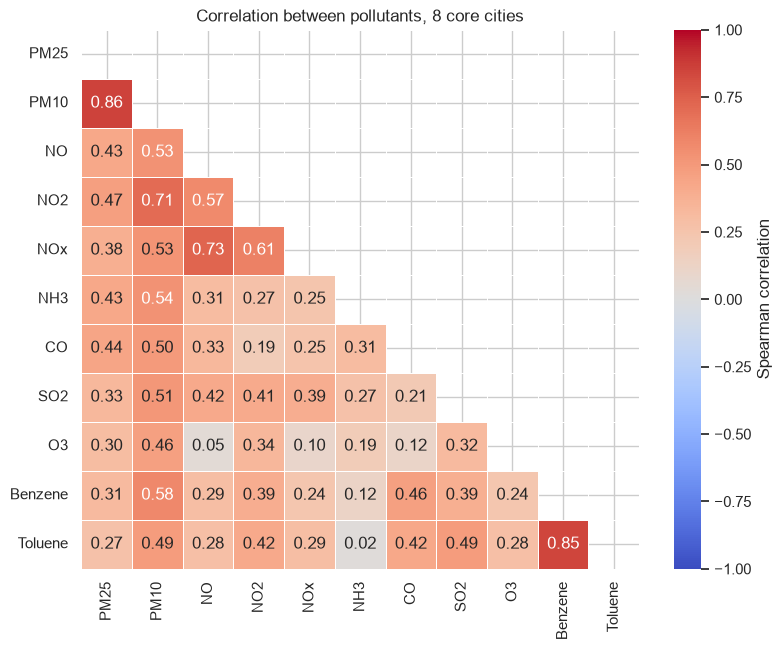

PM10       0.86
NO2        0.47
CO         0.44
NO         0.43
NH3        0.43
NOx        0.38
SO2        0.33
Benzene    0.31
O3         0.30
Toluene    0.27
Name: PM25, dtype: float64
City
Delhi        0.71
Patna        0.09
Lucknow      0.58
Ahmedabad    0.30
Chennai      0.28
Hyderabad    0.41
Bengaluru    0.54
Mumbai       0.79
dtype: float64


In [45]:
corr = df_core[pollutants].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Correlation between pollutants, 8 core cities")
save("17_pollutant_correlation"); plt.show()
print(corr["PM25"].drop("PM25").round(2).sort_values(ascending=False))
by_city = {c: g["PM25"].corr(g["NO2"], method="spearman")
           for c, g in df_core.groupby("City", observed=True)}
print(pd.Series(by_city).round(2).loc[city_order])

### Insight Q17
- **PM2.5 and PM10 correlate at 0.86**, the strongest PM2.5 relationship, which is expected because PM2.5 is a subset of PM10.
- **PM2.5 and the gases are only moderately related:** NO2 0.47, CO 0.44, NO 0.43, NH3 0.43, NOx 0.38, SO2 0.33, Benzene 0.31, O3 0.30, Toluene 0.27.
- **Other strong pairs:** Benzene–Toluene 0.85, NO–NOx 0.73 and NO2–PM10 0.71. The NO–NOx link carries little information because NOx is defined as NO plus NO2.
- **O3 is the least related to the others** (for example 0.05 with NO and 0.10 with NOx), consistent with ozone being formed and destroyed by chemical reactions with nitrogen oxides.
- **The pooled PM2.5–NO2 value (0.47) hides large city differences:** Mumbai 0.79, Delhi 0.71, Lucknow 0.58, Bengaluru 0.54, Hyderabad 0.41, Ahmedabad 0.30, Chennai 0.28 and **Patna only 0.09**. A single pooled number would mislead.
- **Correlation is not causation.** PM2.5 and NO2 may rise together because stagnant winter air traps both, not because one causes the other.

## Q18. Is the PM2.5–NO2 pattern the same in every city? (faceting)
**Method.** The same scatter is split into one panel per city with shared axes and a season colour, so each city's pattern can be compared directly.

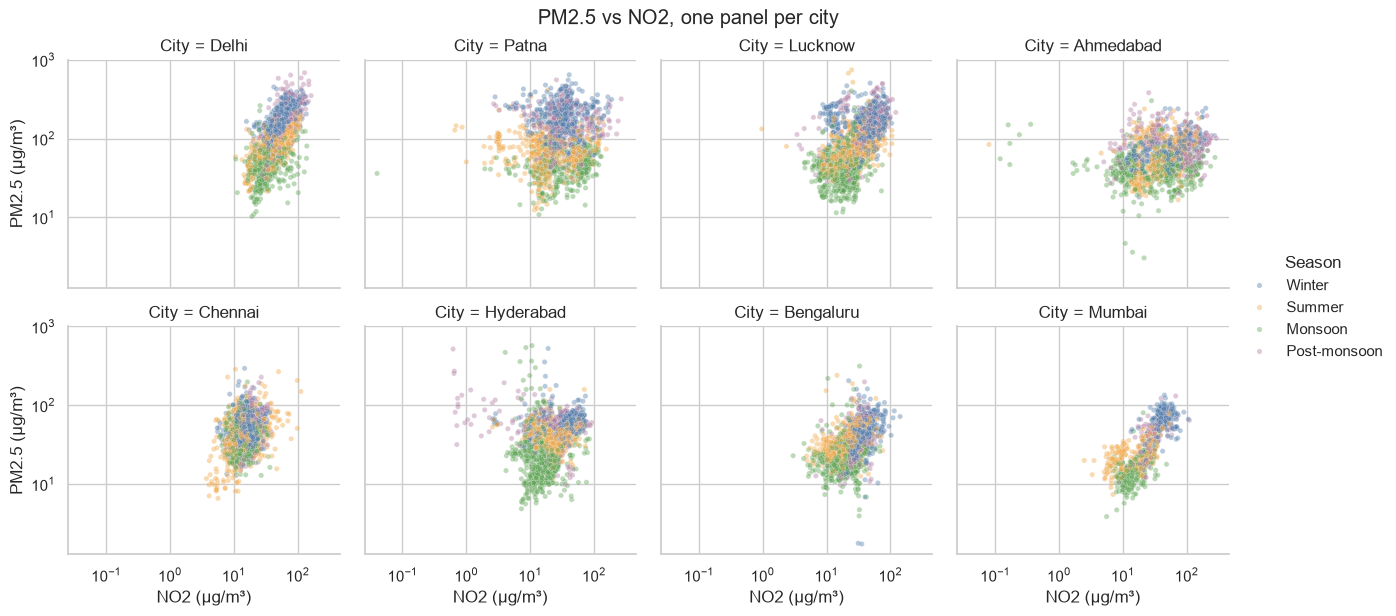

In [46]:
g = sns.relplot(data=df_core.dropna(subset=["PM25", "NO2"]), x="NO2", y="PM25", hue="Season",
                hue_order=season_order, palette=dict(zip(season_order, season_colors)),
                col="City", col_order=list(city_order), col_wrap=4, height=3, aspect=1.05,
                alpha=0.4, s=14, kind="scatter")
g.set(xscale="log", yscale="log")
g.set_axis_labels("NO2 (µg/m³)", "PM2.5 (µg/m³)")
g.figure.suptitle("PM2.5 vs NO2, one panel per city", y=1.02)
g.savefig(FIG / "18_pm25_no2_facets.png", dpi=150, bbox_inches="tight"); plt.show()

### Insight Q18
- **Delhi and Mumbai show tight, upward-sloping clouds**, matching their high correlations (0.71 and 0.79).
- **Patna is a wide, shapeless cloud** with almost no relationship between NO2 and PM2.5 (0.09). Its PM2.5 is high across a wide range of NO2 values, so NO2 is a poor guide to PM2.5 there.
- **A few points with NO2 below 1 µg/m³** appear in Hyderabad, Ahmedabad and Patna. They are far from the rest of each cloud and look like instrument errors; they were not removed and are listed as a limitation.
- **Monsoon points (green) lie at the bottom of every panel**, again showing the seasonal effect.

## Q19. How does the whole PM2.5 distribution shift by season? (KDE)
**Method.** A kernel density estimate (a smooth version of a histogram) of PM2.5 for each season on a log scale. `common_norm=False` scales each curve separately so a season with fewer observations is not drawn smaller.

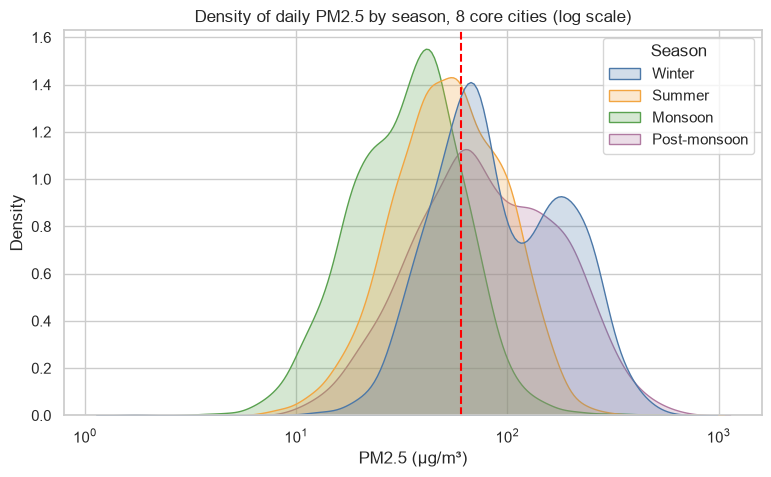

In [47]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=df_core.dropna(subset=["PM25"]), x="PM25", hue="Season", hue_order=season_order,
            palette=dict(zip(season_order, season_colors)), log_scale=True, fill=True,
            common_norm=False, bw_adjust=1, alpha=0.25, ax=ax)
ax.axvline(NAAQS_PM25, color="red", ls="--")
ax.set_title("Density of daily PM2.5 by season, 8 core cities (log scale)")
ax.set_xlabel("PM2.5 (µg/m³)"); ax.set_ylabel("Density")
save("19_pm25_kde_by_season"); plt.show()

### Insight Q19
- **The monsoon curve sits furthest left**, with its peak near 40 µg/m³ and very little density above 100.
- **Winter and post-monsoon are shifted right**, with winter showing a second peak near 180 µg/m³ in addition to its main peak near 65. This is the same double peak seen in the Q4 violin plot.
- **Even in winter many days are below the standard**, because the pooled data includes southern cities. The double peak is probably the mix of northern and southern cities rather than two regimes inside one city; plotting each city group separately would confirm this.

---
# Phase 7: Interactive charts (Q20–Q22)

**Goal.** Let a reader explore the findings instead of reading one fixed view: hover for details, zoom and pan, hide categories from the legend, pick one city from a dropdown, and drag a range slider.

**Output.** Each chart is also saved as a standalone HTML file in `../outputs/` so it can be opened in any browser. GitHub does not render HTML files, so the README uses screenshots.

In [48]:
# Output folder for the interactive HTML files and the city order as plain strings
OUT = Path("../outputs"); OUT.mkdir(exist_ok=True)
cities = [str(c) for c in city_order]

## Q20. How does each city's monthly PM2.5 change, and where is the lockdown window? (dropdown, range slider, legend, hover)
**Method.** A line chart of monthly mean PM2.5 (same data as Q7) with: hover that shows the month, the value and the number of valid days; a **dropdown** to show all cities or just one; a **range slider** under the plot to zoom into any period; clickable legend entries; the red 60 µg/m³ line; and a grey band for the lockdown window. Months with fewer than 20 valid days are gaps.

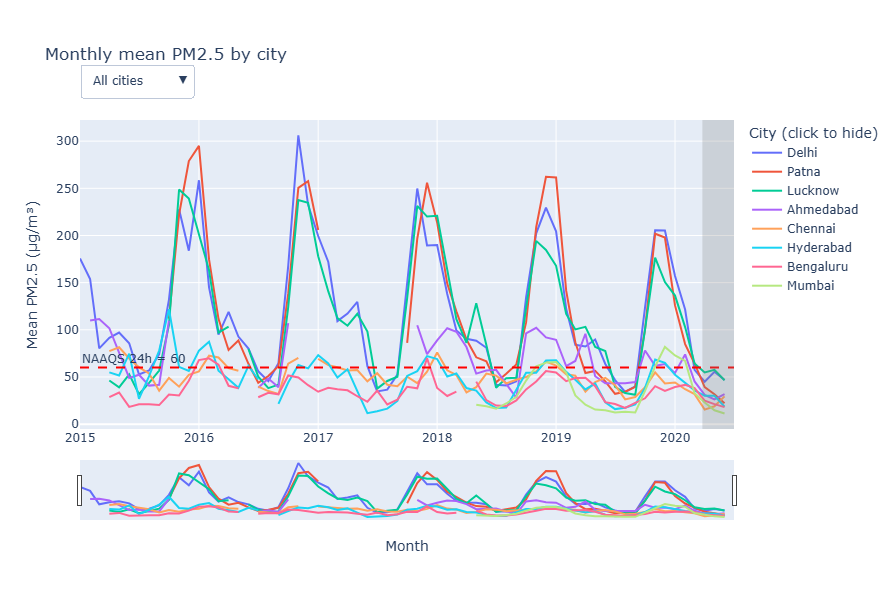

In [49]:
mon_p = mon.copy(); mon_p["City"] = mon_p["City"].astype(str)    # 'mean' is NaN where < 20 valid days
fig = px.line(mon_p, x="Date", y="mean", color="City", category_orders={"City": cities},
              labels={"mean": "Mean PM2.5 (µg/m³)", "Date": "Month", "valid": "Valid days"},
              hover_data={"valid": True, "mean": ":.1f", "City": False},
              title="Monthly mean PM2.5 by city")
assert [t.name for t in fig.data] == cities                      # dropdown below relies on this order

fig.add_hline(y=NAAQS_PM25, line_dash="dash", line_color="red", annotation_text="NAAQS 24h = 60", annotation_position="top left")
fig.add_vrect(x0="2020-03-25", x1="2020-06-30", fillcolor="grey", opacity=0.25, line_width=0)

buttons = [dict(label="All cities", method="update", args=[{"visible": [True] * len(cities)}])]
for i, c in enumerate(cities):
    buttons.append(dict(label=c, method="update", args=[{"visible": [j == i for j in range(len(cities))]}]))
fig.update_layout(updatemenus=[dict(type="dropdown", buttons=buttons, x=0.0, y=1.18, xanchor="left")],
                  hovermode="x unified", legend_title_text="City (click to hide)")
fig.update_layout(height=600, margin=dict(t=120))
fig.update_xaxes(rangeslider_visible=True)
fig.write_html(OUT / "pm25_monthly_interactive.html", include_plotlyjs="cdn")
fig.show()

### Insight Q20
- **Interaction answers a question the static chart cannot.** With all 8 lines on, the chart is crowded. Choosing a city in the dropdown isolates it, and the range slider zooms into 2020, which makes it easy to ask *"How did Chennai alone behave around the lockdown?"* Hover adds the number of valid days, so a reader can see when a value rests on thin data.
- **Delhi, Patna and Lucknow peak every winter at roughly 200–300 µg/m³**; Delhi's highest month is in late 2016 at about 300 µg/m³.
- In April to June 2020 (grey band) all cities are at the low end of their range, but as Q7 and Q10 explain, April–June is naturally the cleaner period.

## Q21. Which city needs attention first, and what is behind the number? (hover)
**Method.** Bars show the share of days above 60 µg/m³ for each city, ordered from highest to lowest and coloured by median PM2.5. Hovering a bar shows the number of valid days, the median and the 90th percentile.

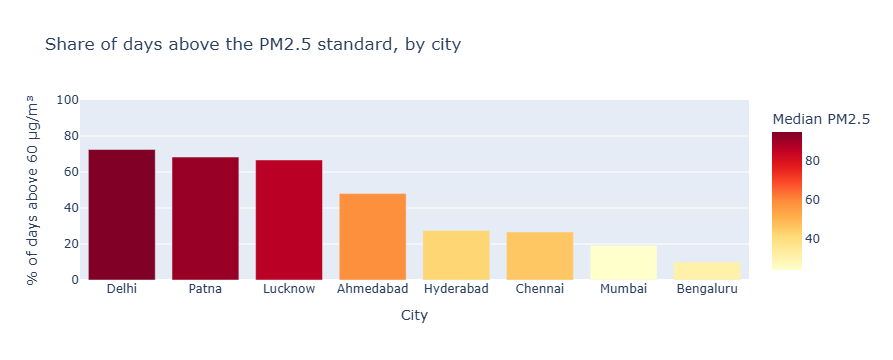

In [50]:
ex = (df_core.dropna(subset=["PM25"]).groupby("City", observed=True)["PM25"]
        .agg(valid_days="count", median="median",
             p90=lambda s: s.quantile(0.9),
             pct_above=lambda s: (s > NAAQS_PM25).mean() * 100).round(1).reset_index())
ex["City"] = ex["City"].astype(str)
ex = ex.sort_values("pct_above", ascending=False)

fig = px.bar(ex, x="City", y="pct_above", color="median", color_continuous_scale="YlOrRd",
             hover_data={"valid_days": True, "median": ":.1f", "p90": ":.1f", "pct_above": ":.1f"},
             labels={"pct_above": "% of days above 60 µg/m³", "median": "Median PM2.5",
                     "p90": "90th percentile", "valid_days": "Valid days"},
             title="Share of days above the PM2.5 standard, by city")
fig.update_layout(coloraxis_colorbar_title="Median PM2.5", yaxis_range=[0, 100])
fig.write_html(OUT / "pm25_exceedance_interactive.html", include_plotlyjs="cdn")
fig.show()

### Insight Q21
- **Delhi (72.5%), Patna (68.3%) and Lucknow (66.7%)** have the highest shares of days above the standard and also the highest medians (dark colours), so they are the clear first priority.
- **Ahmedabad (48.0%)** is in the middle; Hyderabad (27.5%), Chennai (26.7%), Mumbai (19.3%) and Bengaluru (10.0%) are lowest.
- **The hover text matters for Mumbai:** it shows only 789 valid days, so the 19.3% rests on less than 40% of the period.

## Q22. Where are the cities with the worst PM2.5? (bubble map)
**Method.** A map with one bubble per core city: **size = median PM2.5**, **colour = share of days above 60 µg/m³**. The data is city-level, so a *bubble map* is used instead of a choropleth, which would need state-level data and would imply information the dataset does not have. City coordinates are entered by hand (approximate city centres).

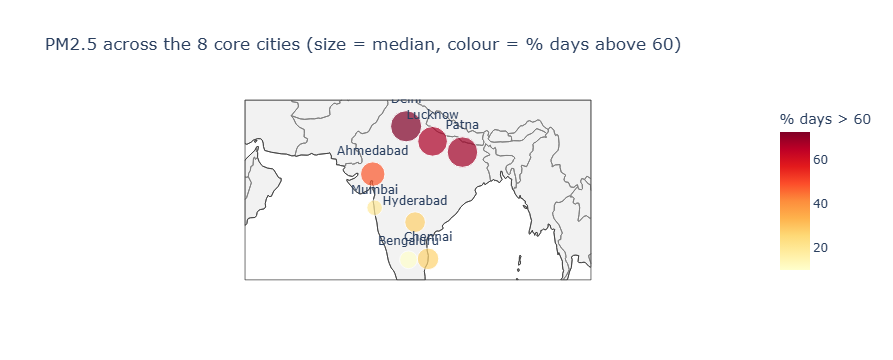

In [51]:
coords = {"Delhi": (28.61, 77.21), "Patna": (25.59, 85.14), "Lucknow": (26.85, 80.95),
          "Ahmedabad": (23.02, 72.57), "Chennai": (13.08, 80.27), "Hyderabad": (17.39, 78.49),
          "Bengaluru": (12.97, 77.59), "Mumbai": (19.08, 72.88)}
ex["lat"] = ex["City"].map(lambda c: coords[c][0])
ex["lon"] = ex["City"].map(lambda c: coords[c][1])

fig = px.scatter_geo(ex, lat="lat", lon="lon", size="median", color="pct_above", hover_name="City", text="City",
                     hover_data={"lat": False, "lon": False, "valid_days": True, "median": ":.1f",
                                 "pct_above": ":.1f"},
                     color_continuous_scale="YlOrRd", size_max=22, projection="natural earth",
                     labels={"pct_above": "% days > 60", "median": "Median PM2.5"},
                     title="PM2.5 across the 8 core cities (size = median, colour = % days above 60)")
fig.update_traces(textposition="top center")
fig.update_geos(fitbounds="locations", showcountries=True, countrycolor="grey",
                showland=True, landcolor="#f2f2f2")
fig.write_html(OUT / "pm25_city_map.html", include_plotlyjs="cdn")
fig.show()

### Insight Q22
- **The worst cities are geographically clustered.** Delhi, Lucknow and Patna lie along the northern Indo-Gangetic region and have the largest and darkest bubbles.
- **Ahmedabad (orange) sits between the north and the south**, while the southern and western cities (Hyderabad, Chennai, Bengaluru, Mumbai) have small, pale bubbles.
- **Limitation.** Only 8 cities are shown, so the map cannot say anything about the rest of India, and bubbles of nearby northern cities can overlap (use the map's zoom to separate them).

### Evaluation of the interactive charts
- **Interactive features demonstrated:** hover details, dropdown selection, a range slider, clickable legend entries and zoom/pan, all in the Q20 chart.
- **A question easier to answer interactively:** how one city behaves in one period (for example Chennai in 2020) without the other seven lines in the way.
- **Limitations.** With all cities visible the lines overlap; interactive controls do not appear in a printed page or a screenshot; the HTML files need a browser and internet access to load the Plotly library; and dropdowns are harder to use on a small screen.

---
# Phase 8: Key findings, limitations and conclusion

## 8.1 Key findings
1. **Pollution is concentrated in the north and peaks in winter.** PM2.5 exceeded the 60 µg/m³ standard on **72.5% of measured days in Delhi, 68.3% in Patna and 66.7% in Lucknow**, against 10.0% in Bengaluru. The share of days rated Poor or worse (AQI) was 65.1%, 53.5% and 49.4% in those three cities and 2.1–6.7% in Bengaluru, Hyderabad, Mumbai and Chennai.
2. **Season is the strongest driver.** Median PM2.5 across the core cities is 81.1 µg/m³ in winter, 75.6 post-monsoon, 53.1 in summer and 34.9 in monsoon (winter ≈ 2.3 × monsoon). Patna has the highest winter median (196.2), and Chennai's seasonal swing is nearly flat (1.3×).
3. **Delhi's seasonality is multiplicative and peaks in November.** The seasonal swing grows with the pollution level (residual–trend correlation 0.04 multiplicative vs 0.20 additive); November is the worst month, not December or January.
4. **Pollution fell after 2016 in most cities.** Delhi's yearly mean dropped from 138.5 (2016) to 108.5 µg/m³ (2019), a fall of about 22%.
5. **Lockdown window (25 Mar–30 Jun 2020).** PM2.5 was 31–56% lower than on the same dates in 2016–19 and 25–54% lower than in 2019 alone (7 cities with enough baseline data; Delhi −48% and −40%). NO2 fell more than PM2.5 in only 4 of 7 cities. These are observed differences, not proof of cause.
6. **Pollutant relationships.** PM2.5 correlates 0.86 with PM10 but only 0.27–0.47 with the gases. The PM2.5–NO2 correlation varies from 0.09 (Patna) to 0.79 (Mumbai), so a pooled value is misleading.
7. **Two data-quality faults were found and handled.** CO was an exact copy of NO in 1,322 rows (65.6% of Ahmedabad's rows), and Ahmedabad's AQI followed NO (ρ = 0.88) instead of PM2.5 (ρ = 0.50), unlike Delhi's AQI (ρ = 0.92 with PM2.5). The AQI series was excluded and the problem documented.

## 8.2 Chart critique summary
- **Raw-scale histogram (Q1, panel A):** hides the shape of a long-tailed distribution. Fixed with a log scale, and with a clipped version that states what it hides.
- **Stacked bars of absolute counts (Q12):** confuse pollution with the number of measured days. Fixed with a normalized version that prints each city's sample size (Q13).
- **Pooled correlations and pooled season medians (Q4, Q17):** hide city differences. Fixed by repeating the analysis by city (Q11, Q18).

## 8.3 Limitations
- **Uneven coverage.** Only 8 of 26 cities have near-complete records. Mumbai has PM2.5 on only 39% of days, Ahmedabad on about 70%, and Mumbai's seasonal ratios and exceedance figures are the least certain.
- **Gap filling is an estimate.** Interpolation is limited to gaps of 3 days or fewer; long gaps remain empty and cities are not interpolated across.
- **The lockdown comparison cannot separate causes.** It uses between 1 and 4 baseline years per city, and weather and rainfall differ between years. Pollution was also already falling before 2020, which is why two baselines are reported.
- **One calendar definition of season for all cities.** Monsoon timing differs between regions (for example, Chennai receives much of its rain later in the year), so the season labels are an approximation.
- **Remaining data problems.** A few NO2 readings below 1 µg/m³ look like instrument errors and were not removed; PM10 is capped at 1,000; the CO copy error is a probable, but not proven, cause of Ahmedabad's AQI problem.
- **City-level data only.** The map is a bubble map with hand-entered city coordinates; no state-level or station-level analysis is possible.
- **Seasonal causes are not tested.** Explanations such as crop-residue burning or stagnant winter air are context from other sources, not results of this analysis.

## 8.4 Conclusion
Air quality in the 8 best-measured Indian cities splits into two groups. **Delhi, Patna and Lucknow** are above the national PM2.5 standard on roughly two days in three and have strong winter peaks with monthly means of roughly 200–300 µg/m³; the other five cities are cleaner (between 10% and 48% of days above the standard), with seasonal swings that range from small (Chennai) to moderate. Pollution was lower in the 2020 lockdown window than in the same dates of earlier years in every city examined, but the size of the drop depends strongly on the baseline, and some of it reflects a decline that began before 2020.

The project also shows why visual analysis must be paired with data auditing: a ranking of cities by AQI would have put Ahmedabad first, and only by checking which pollutants the AQI actually follows could that result be shown to be unreliable.


---
*End of notebook. Outputs: `../data/processed/city_day_clean.csv`, `../outputs/figures/*.png`, and the interactive HTML files in `../outputs/`.*